# Berkshire: answers to the team’s 23 Objectives
## Dataset-only assessment and common visualization specifications, 2017–2024

This notebook follows **Objectives Q1–Q23** in [Project Objectives – Shared Questions](https://docs.google.com/document/d/1Ba0FULReclAJJYfoqGe-NrArqX9EutvvRWoEKeXDgfs/edit?tab=t.0). It does **not** follow the later “FINAL QUESTIONS LIST.” Norfolk-specific questions are deferred.

**Only three analytical sources are used:** `charges filed info.xlsx`, `disposed info.xlsx`, and `bail info.xlsx` in this folder. No external population counts, policy dates, statewide statistics, crime lists, or other-county datasets are loaded. The shared document supplies question wording and team criteria, not analytical numbers.

Each question receives an answerability status, an answer or an explicit reason it cannot be answered, and a visualization where the data support one. A nearby observable quantity is labeled as a **companion analysis**, never silently substituted for the question. Unsupported questions have no invented result or decorative chart.

**Run:** use the packages in `requirements_eda.txt`; restart the kernel and Run All from this folder or its parent. The notebook contains all required analysis code. Results are embedded and also saved to `objectives_23_outputs/`. Original workbooks and the earlier EDA notebook are left unchanged. No network access is needed.

### How to interpret the status

- **Answerable:** the literal requested quantity is observable in its stated population.
- **Partial:** a defined part or a qualified proxy is observable; the exact full question remains unsupported.
- **Not answerable:** a required field or denominator is absent. The missing input is stated.
- **Insufficient data:** the field exists, but the relevant coverage fails the team’s 20% missingness rule.

This is a feasibility study for common team goals. A Berkshire result alone does not establish that another county can reproduce it. The final tables include a reusable metric contract and all 23 answers.

This GitHub copy includes aggregate chart outputs. Open the figure gallery from the project README for a separate view. Local execution requires the project source extracts.

## Analysis contract and differences from the earlier charge-level EDA

1. **2017–2024 only.** Filing analyses use source initiation date. Disposition analyses use the latest recorded disposition date for a case, restricted to the window; cases with a later 2025 disposition are excluded from that population. Bail events use their recorded status date. These are different populations and are labeled separately.
2. **Case unit:** `(internal case ID, defendant ID)` is the available stable case-defendant key. The team specifies docket per defendant, but records can contain both District and Superior Court dockets. No arbitrary docket choice or transfer merger is imposed. A docket audit shows this limitation. Counts are described as recorded case-defendant units until the team agrees a docket rule.
3. **Criminal scope:** a case has at least one `F`, `M+`, or `M-` charge. `CM` and Unknown-only cases are displayed separately and excluded from criminal-outcome comparisons. The representative charge is the highest **source class**, with charge-code/count tie-breaks. This does not establish statutory seriousness within a class; no external crime list is used.
4. **Disposed case proxy:** source status is Closed across available rows, a criminal charge is present, and the case’s latest valid recorded disposition date is in 2017–2024. This cannot prove every underlying count was extracted or that the case was finally closed as of that historical date. Current statuses are not historical snapshots.
5. **Outcome classification is provisional.** The visible crosswalk retains CWOF separately from conviction and diversion. Contradictory CWOF/actual-jail fields and unresolved outcomes remain Unknown/review. No undocumented program participation is inferred. For a case with resolved mixed outcomes, a stated hierarchy selects one bucket; unresolved charge results override that selection unless an explicit trial-conviction marker already establishes the highest displayed outcome.
6. **Coverage first.** Unknown stays in denominators. Headline dependent rates are withheld when relevant unknown/missingness exceeds 20%. Comparative groups need at least 30 cases. Source-available subset diagnostics are explicitly labeled and do not become county-wide rates.
7. **No causal interpretation.** Judges, race, recorded sex, agencies, courts, or bail statuses are not randomly assigned. Case facts, prior record, complete referrals, actual payments, and population exposure are unavailable. Charges are allegations, not proof of offending.

In [1]:
from pathlib import Path
import calendar
import hashlib
import json
import platform
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display, Markdown
import openpyxl

warnings.filterwarnings('ignore', category=FutureWarning)
START = pd.Timestamp('2017-01-01')
END = pd.Timestamp('2024-12-31')
FOLLOWUP_END = pd.Timestamp('2025-12-31')
MIN_CELL = 30
TOP_N = 12
DATA_DIR = Path.cwd()
if not (DATA_DIR / 'charges filed info.xlsx').exists():
    DATA_DIR = DATA_DIR / 'berkshire'
assert (DATA_DIR / 'charges filed info.xlsx').exists(), 'Run from the Berkshire folder or its parent.'
OUT = DATA_DIR / 'objectives_23_outputs'
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
(OUT / 'tables').mkdir(exist_ok=True)
TABLES, FINDINGS, FIGURES = {}, [], []

COLORS = ['#205072','#2c8c86','#e0a13a','#b75453','#7f7099','#69a5cc','#8f9779','#c388a3','#777777','#b7c2cb']
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':150, 'font.family':'DejaVu Sans',
                     'font.size':10, 'axes.titlesize':14, 'axes.labelsize':10,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.prop_cycle':plt.cycler(color=COLORS)})
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_colwidth', 65)

def note(text):
    FINDINGS.append(text)
    display(Markdown('**Readout.** ' + text))

def table(name, frame, rows=20, digits=2):
    frame = frame.to_frame() if isinstance(frame, pd.Series) else frame.copy()
    TABLES[name] = frame
    frame.to_csv(OUT / 'tables' / f'{name}.csv', index=True)
    display(frame.head(rows).round(digits))
    if len(frame) > rows:
        display(Markdown(f'Showing {rows:,} of {len(frame):,} rows. Complete table: `eda_outputs/tables/{name}.csv`.'))
    return frame

def finish(fig, name, caption):
    fig.text(.01, .01, caption, fontsize=8, color='#4f5c66', wrap=True)
    fig.tight_layout(rect=(0,.07,1,.98))
    fig.savefig(OUT / 'figures' / f'{name}.png', bbox_inches='tight')
    FIGURES.append(name)
    plt.show()
    plt.close(fig)

def barh(series, title, xlabel='Recorded charge rows', color=None):
    series = series.sort_values()
    fig, ax = plt.subplots(figsize=(11,max(4, .36*len(series)+1.3)))
    ax.barh([str(x) for x in series.index], series.values, color=color or COLORS[0])
    ax.set(title=title, xlabel=xlabel)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
    for i, value in enumerate(series.values):
        ax.text(value, i, f' {value:,.0f}', va='center', fontsize=9)
    ax.margins(x=.18)
    return fig, ax

def stacked(frame, title, percent=False):
    frame = frame.copy()
    if percent:
        frame = frame.div(frame.sum(axis=1).replace(0,np.nan), axis=0)*100
    fig, ax = plt.subplots(figsize=(12,6))
    frame.plot.bar(stacked=True, ax=ax, color=COLORS[:len(frame.columns)], width=.8)
    ax.set(title=title, ylabel='Share within group (%)' if percent else 'Recorded charge rows', xlabel='')
    ax.tick_params(axis='x', labelrotation=35)
    if percent: ax.set_ylim(0,100)
    ax.legend(title='', bbox_to_anchor=(1.01,1), loc='upper left', fontsize=8)
    return fig, ax

def heatmap(frame, title, percent=False, annotate=False, cmap='Blues'):
    frame=frame.dropna(how='all').dropna(axis=1,how='all')
    if frame.empty:
        fig,ax=plt.subplots(figsize=(10,4))
        ax.text(.5,.5,'Insufficient data after the reporting threshold',ha='center',va='center',transform=ax.transAxes)
        ax.set_title(title);ax.set_axis_off()
        return fig,ax
    fig, ax = plt.subplots(figsize=(max(9,.72*len(frame.columns)),max(4,.4*len(frame)+1.8)))
    arr = frame.to_numpy(dtype=float)
    im = ax.imshow(np.ma.masked_invalid(arr), aspect='auto', cmap=cmap,
                   vmin=0)
    ax.set_xticks(range(len(frame.columns)), [str(c) for c in frame.columns], rotation=40, ha='right')
    ax.set_yticks(range(len(frame)), [str(i) for i in frame.index])
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label='Percent' if percent else 'Charge rows')
    if annotate:
        midpoint = np.nanmax(arr)/2
        for i in range(len(frame)):
            for j in range(len(frame.columns)):
                value=arr[i,j]
                ax.text(j,i, '—' if np.isnan(value) else f'{value:.0f}', ha='center',va='center',
                        color='white' if value>midpoint else '#263746',fontsize=8)
    return fig, ax

def in_window(series, end=END):
    return series.between(START,end)

def parse_date(series):
    # Keep raw columns separately. Malformed centuries are flagged, not guessed.
    parsed = pd.to_datetime(series, format='mixed', errors='coerce')
    years = parsed.dt.year
    return parsed.where(years.between(1900,2026)).astype('datetime64[ns]')

def normalize_id(series):
    return series.map(lambda x: str(int(x)) if isinstance(x,(float,np.floating)) and pd.notna(x) and x.is_integer()
                      else str(x).strip() if pd.notna(x) else pd.NA).astype('string')

def load_workbook(path):
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    frames, header = [], None
    for sheet in wb:
        values = sheet.values
        first = next(values)
        if header is None:
            header = [str(v).strip() for v in first]
            rows, first_excel_row = list(values), 2
        elif [str(v).strip() for v in first] == header:
            rows, first_excel_row = list(values), 2
        else:
            rows, first_excel_row = [first] + list(values), 1
        part = pd.DataFrame(rows, columns=header)
        part['source_sheet'] = sheet.title
        part['source_row'] = np.arange(first_excel_row, first_excel_row+len(part))
        frames.append(part)
    wb.close()
    frame = pd.concat(frames, ignore_index=True)
    for column in header:
        frame[column] = frame[column].map(lambda x: x.strip() if isinstance(x,str) else x)
        frame[column] = frame[column].replace(r'^\s*$', pd.NA, regex=True)
    return frame

## Load and audit the three local workbooks

Both List_Frame sheets are combined. Sheet two begins with data, not another header. Exact repeats are flagged and removed only for case construction; original charge-row counts remain available for Q21. Original cells and dates are retained for audit.

In [2]:
paths = {'filed':DATA_DIR/'charges filed info.xlsx',
         'disposed':DATA_DIR/'disposed info.xlsx', 'bail':DATA_DIR/'bail info.xlsx'}
source_hashes = {name:hashlib.sha256(path.read_bytes()).hexdigest() for name,path in paths.items()}
raw = {name:load_workbook(path) for name,path in paths.items()}
inventory=[]
for name, frame in raw.items():
    cols=[c for c in frame if not c.startswith('source_')]
    frame['exact_duplicate'] = frame.duplicated(cols, keep='first')
    for sheet, sub in frame.groupby('source_sheet', sort=False):
        inventory.append({'extract':name,'sheet':sheet,'rows':len(sub),
                          'source_columns':len(cols),'repeated_export_rows':int(sub.exact_duplicate.sum())})
table('source_inventory',pd.DataFrame(inventory))
assert len(raw['filed']) == 77250 and len(raw['disposed']) == 72896 and len(raw['bail']) == 25420
assert raw['filed'].query("source_sheet == 'List_Frame_2'").source_row.min() == 1
note('Both continuation sheets are included without losing their first data row. Source-row tables retain flagged repeated rows; case construction removes exact repeated exports; none of the original Excel files is written to.')

In [3]:
filed = raw['filed'].rename(columns={'CaseNo':'case_id','Id Prsn Dfndnt':'person_id',
 'Offense Dt':'offense_raw','Initiated Dt':'initiated_raw','Chrg Cnt':'count_no',
 'Chrg Code':'charge_code','Chrg Desc':'charge_description','Offns Class':'offense_class',
 'Race':'race_code','Gender':'sex_code','Ofcr Agncy':'agency','Current or Last Court':'court'}).copy()
disposed = raw['disposed'].rename(columns={'Nmbr Cs':'case_id','Id Prsn Dfndnt':'person_id',
 'Offense Dt':'offense_raw','Initiated Dt':'initiated_raw','Chrg Cnt':'count_no',
 'Chrg Code':'charge_code','Chrg Desc':'charge_description','Offns Class':'offense_class',
 'Race':'race_code','Gender':'sex_code','Officer Agncy':'agency','Court':'court',
 'Judge':'judge','Disp Dt':'disposed_raw','Disp Type':'disp_type','Disp Desc':'disp_description',
 'Sentence Translation':'sentence_translation'}).copy()
bail = raw['bail'].rename(columns={'Nmbr Cs':'case_id','Race':'race_code','Sex':'sex_code',
 'Date Sts':'bail_raw','Desc Dfndnt Sts':'bail_status','Bail Req':'requested','Bail Set':'set_amount',
 'Case Type':'case_type','Crime Type':'crime_type'}).copy()
race_map={'W':'White','B':'Black','H':'Hispanic (source race field)','A':'Asian','U':'Unknown (U)'}
sex_map={'M':'Male','F':'Female','U':'Unknown (U)'}
date_audit=[]
for name, frame in [('filed',filed),('disposed',disposed),('bail',bail)]:
    frame['case_id']=normalize_id(frame.case_id)
    if 'person_id' in frame:
        frame['person_id']=normalize_id(frame.person_id)
        frame['case_person']=frame.case_id+' | '+frame.person_id
        frame['charge_code']=normalize_id(frame.charge_code)
        frame['count_no']=normalize_id(frame.count_no)
        frame['offense_class']=frame.offense_class.fillna('Unknown')
        frame['criminal_charge']=frame.offense_class.isin(['F','M+','M-'])
        frame['placeholder_charge']=frame.charge_code.isin(['666666','999999'])
    for source, target in [('offense_raw','offense_date'),('initiated_raw','initiated_date'),
                           ('disposed_raw','disposition_date'),('bail_raw','bail_date')]:
        if source in frame:
            frame[target]=parse_date(frame[source])
            date_audit.append({'extract':name,'field':source,'blank':int(frame[source].isna().sum()),
              'invalid_or_outside_1900_2026':int((frame[source].notna()&frame[target].isna()).sum()),
              'valid_min':frame[target].min(),'valid_max':frame[target].max()})
    frame['race']=frame.race_code.map(lambda x: 'Missing' if pd.isna(x) else race_map.get(x,f'Code {x} (unverified)'))
    frame['sex']=frame.sex_code.map(lambda x: 'Missing' if pd.isna(x) else sex_map.get(x,f'Code {x} (unverified)'))
filed['filing_year']=filed.initiated_date.dt.year
filed['filing_month']=filed.initiated_date.dt.month
disposed['disposition_year']=disposed.disposition_date.dt.year
f=filed.loc[in_window(filed.initiated_date)].copy()
d=disposed.loc[in_window(disposed.disposition_date)].copy()
b=bail.loc[in_window(bail.bail_date)].copy()
for c in ['requested','set_amount']:
    b[c]=pd.to_numeric(b[c],errors='coerce')
table('date_validation',pd.DataFrame(date_audit))
cohorts=pd.DataFrame({'rows':[len(f),len(d),len(b)],
 'case_ids':[f.case_id.nunique(),d.case_id.nunique(),b.case_id.nunique()],
 'case_defendant_pairs':[f.case_person.nunique(),d.case_person.nunique(),np.nan]},
 index=['Filed in 2017–2024','Disposed in 2017–2024','Bail dated 2017–2024'])
table('analysis_populations',cohorts)
coverage=[]
for name, frame, fields in [('Filed',f,['race_code','sex_code','offense_date','offense_class','agency','court']),
 ('Disposed',d,['race_code','sex_code','judge','disp_type','disp_description','sentence_translation','offense_date']),
 ('Bail',b,['race_code','sex_code','requested','set_amount','crime_type'])]:
    for field in fields:
        missing=frame[field].isna() | (frame[field].eq('Unknown') if field=='offense_class' else False)
        coverage.append({'extract':name,'field':field,'rows':len(frame),'missing':int(missing.sum()),
                         'missing_pct':missing.mean()*100})
coverage=pd.DataFrame(coverage)
table('coverage_by_population',coverage,rows=30)
fig,ax=barh(coverage.set_index(coverage.extract+' / '+coverage.field).missing_pct,
            'Coverage gaps differ sharply by field', 'Missing within stated population (%)')
ax.axvline(20,color=COLORS[3],ls='--',label='Team threshold: 20%');ax.legend()
finish(fig,'01_field_coverage','Missingness across all rows; conditional sentencing/cash-bail denominators are assessed separately below.')
note(f'The study contains {len(f):,} filed charge rows, {len(d):,} disposed charge rows, and {len(b):,} bail events. Dates outside 1900–2026 are flagged, never repaired by guessing a century.')

## Build case-level analysis tables and a transparent provisional crosswalk

The primary outcome hierarchy is: **trial conviction > guilty plea > conviction with unknown route > CWOF > acquittal > nolle prosequi > dismissal > other resolved**. CWOF/continuation/program labels are not collapsed. A case containing an unclassified criminal charge becomes **Unknown / review** unless an explicit trial-conviction marker already establishes the top category. This is a reproducible analytical rule, not client sign-off or a legal determination.

For sentencing, only source-indicated conviction cases are eligible. An explicit custodial sentence translation establishes the top sentence type. Otherwise, missing sentence information on a conviction charge makes the case sentence Unknown rather than assumed noncustodial. An actual-jail number without a clear custodial translation is not sufficient on its own.

In [4]:
def classify_outcome(row):
    typ=str(row.get('disp_type','')).strip()
    desc=str(row.get('disp_description','')).strip()
    sentence=str(row.get('sentence_translation','')).strip()
    actual_values=[pd.to_numeric(row.get(c),errors='coerce') for c in
                   ['Min Actl Jaill Impsd Term','Max Actl Jail Imp Term']]
    positive_actual=any(pd.notna(x) and x>0 for x in actual_values)
    text_custody=sentence in ['Jail','Jail (Time Served)','Split Sentence','Committed']
    cwof=sentence=='Continued w/o Finding' or typ=='Continued Without Finding'
    if cwof and (positive_actual or text_custody): return 'Conflicting CWOF / custody markers'
    if typ=='Plea':
        if cwof:return 'Plea · CWOF'
        if text_custody or positive_actual:return 'Plea · custody marker'
        if sentence in ['Probation','Suspended Sentence']:return 'Plea · probation / suspended'
        if sentence in ['Fines','Court Cost/Restitution','Community Service','House Arrest']:return 'Plea · other sentence marker'
        if sentence in ['Filed','Filed w/o Change of Plea']:return 'Plea · filed'
        if sentence=='Continued w/o Change of Plea':return 'Continued without change of plea'
        return 'Plea · sentence unresolved'
    if typ.startswith('Dismissed'):return 'Dismissed (all source variants)'
    if typ=='Nolle Prosequi':return 'Nolle prosequi'
    if typ=='Trial':
        if desc in ['Not Guilty','Required Finding of Not Guilty','Directed Verdict']:return 'Trial · not guilty marker'
        if desc=='Guilty':return 'Trial · guilty marker'
        return 'Trial · result unresolved'
    if typ=='Guilty':return 'Guilty · route unspecified'
    if typ in ['Not Guilty','Required Finding of Not Guilty','Directed Verdict']:return 'Not guilty / directed verdict'
    if cwof:return 'CWOF · explicit type'
    if typ=='Continued Without Change of Plea':return 'Continued without change of plea'
    if typ in ['Responsible','Not Responsible','Converted to Civil']:return 'Civil / responsibility result'
    return 'Other / review required'

In [5]:
ANSWERS={}
CONTRACTS=[]
def answer(number,status,text,limitation,unit,denominator):
    ANSWERS[number]={'question':number,'status':status,'answer':text,'limitation_or_missing_input':limitation,
                     'unit':unit,'denominator':denominator}
    display(Markdown(f'**Answerability: {status}.** {text}\n\n**Limit / missing input:** {limitation}'))

def contract(number,chart,unit,period,numerator,denominator,unknown,extra='None'):
    CONTRACTS.append({'question':number,'suggested_uniform_visual':chart,'unit':unit,'period':period,
      'numerator':numerator,'denominator':denominator,'unknown_handling':unknown,'additional_input_needed':extra})

def single_value(series,missing='Missing'):
    values=series.dropna().astype(str).unique()
    return missing if len(values)==0 else values[0] if len(values)==1 else 'Multiple / conflicting'

filed_clean=filed.loc[~filed.exact_duplicate].copy()
disposed_clean=disposed.loc[~disposed.exact_duplicate].copy()
class_rank={'F':4,'M+':3,'M-':2,'CM':1,'Unknown':0}
for frame in [filed_clean,disposed_clean]:
    frame['class_rank']=frame.offense_class.map(class_rank).fillna(0)
    frame['charge_token']=frame.count_no+' | '+frame.charge_code

canonical=filed_clean.groupby('charge_code').charge_description.agg(
    lambda s:s.dropna().mode().iloc[0] if s.notna().any() else 'Unknown description')
labels={c:f'{c} · {str(t)[:55]}' for c,t in canonical.items()}

def base_cases(frame,date_field):
    result=frame.groupby('case_person').agg(case_id=('case_id','first'),person_id=('person_id','first'),
      initiation=('initiated_date','min'),offense_date=('offense_date','min'),
      recorded_charge_tokens=('charge_token','nunique'),any_criminal=('criminal_charge','max'))
    ranked=frame.sort_values(['case_person','class_rank','charge_code','count_no'],ascending=[True,False,True,True])
    representative=ranked.drop_duplicates('case_person').set_index('case_person')
    result['source_class']=representative.offense_class
    result['representative_code']=representative.charge_code
    result['representative_description']=representative.charge_description
    result['race']=frame.groupby('case_person').race.agg(single_value)
    result['sex']=frame.groupby('case_person').sex.agg(single_value)
    result['court']=frame.groupby('case_person').court.agg(single_value)
    result['year']=result[date_field].dt.year if date_field in result else np.nan
    return result

filing_cases_all=base_cases(filed_clean,'initiation')
fc=filing_cases_all.loc[in_window(filing_cases_all.initiation)].copy()
fc['year']=fc.initiation.dt.year.astype(int)
fc_criminal=fc.loc[fc.any_criminal].copy()

# Docket coverage is audited, not resolved by guessing which court docket is the case.
docket_pairs=filed_clean[['case_person','DistCt Dckt','SupCt Dckt']].copy()
table('case_and_docket_key_audit',pd.Series({
 'internal_case_defendant_units_in_filing_window':len(fc),
 'criminal_case_defendant_units':len(fc_criminal),
 'filed_case_units_with_any_district_docket':docket_pairs.loc[docket_pairs['DistCt Dckt'].notna()].case_person.nunique(),
 'filed_case_units_with_any_superior_docket':docket_pairs.loc[docket_pairs['SupCt Dckt'].notna()].case_person.nunique(),
 'rows_with_both_docket_fields':int(docket_pairs[['DistCt Dckt','SupCt Dckt']].notna().all(axis=1).sum()),
 'district_docket_defendant_pairs_full_filed_extract':filed_clean.loc[filed_clean['DistCt Dckt'].notna(),['DistCt Dckt','person_id']].drop_duplicates().shape[0]
},name='count'))

disposed_clean['detail']=disposed_clean.apply(classify_outcome,axis=1)
bucket_map={
 'Plea · custody marker':'Guilty plea', 'Plea · probation / suspended':'Guilty plea',
 'Plea · other sentence marker':'Guilty plea', 'Plea · CWOF':'CWOF', 'CWOF · explicit type':'CWOF',
 'Trial · guilty marker':'Trial conviction', 'Trial · not guilty marker':'Acquittal',
 'Not guilty / directed verdict':'Acquittal', 'Guilty · route unspecified':'Conviction · route unknown',
 'Dismissed (all source variants)':'Dismissal', 'Nolle prosequi':'Nolle prosequi',
 'Civil / responsibility result':'Civil / responsibility',
 'Continued without change of plea':'Other continuation',
 'Plea · filed':'Filed · result unclear'}
disposed_clean['bucket']=disposed_clean.detail.map(bucket_map).fillna('Unknown / review')
conviction_buckets=['Trial conviction','Guilty plea','Conviction · route unknown']
disposed_clean['conviction_marker']=disposed_clean.bucket.isin(conviction_buckets)
sentence_map={'Jail':'Incarceration','Jail (Time Served)':'Incarceration','Split Sentence':'Incarceration',
 'Committed':'Incarceration','Probation':'Probation / suspended','Suspended Sentence':'Probation / suspended',
 'Fines':'Fines / other','Court Cost/Restitution':'Fines / other','Community Service':'Fines / other','House Arrest':'Fines / other'}
disposed_clean['sentence_type']=disposed_clean.sentence_translation.map(sentence_map).fillna('Unknown')
disposed_clean.loc[~disposed_clean.conviction_marker,'sentence_type']='Not eligible'

dc_all=base_cases(disposed_clean,'initiation')
dc_all['last_disposition']=disposed_clean.groupby('case_person').disposition_date.max()
dc_all['first_disposition']=disposed_clean.groupby('case_person').disposition_date.min()
dc_all['closed_source_status']=disposed_clean.groupby('case_person')['Status'].agg(
    lambda s:s.notna().all() and s.eq('Closed').all())
dc_all['invalid_disposition_date']=disposed_clean.groupby('case_person').apply(
    lambda g:(g.disposed_raw.notna()&g.disposition_date.isna()).any(),include_groups=False)
criminal_rows=disposed_clean.loc[disposed_clean.criminal_charge].copy()
order=['Unknown / review','Filed · result unclear','Other continuation','Civil / responsibility',
       'Dismissal','Nolle prosequi','Acquittal','CWOF','Conviction · route unknown','Guilty plea','Trial conviction']
rank={name:i for i,name in enumerate(order)}
def case_bucket(group):
    values=set(group.bucket)
    if 'Trial conviction' in values:return 'Trial conviction'
    if values & {'Unknown / review','Filed · result unclear'}:return 'Unknown / review'
    return max(values,key=lambda x:rank[x])
dc_all['outcome']=criminal_rows.groupby('case_person').apply(case_bucket,include_groups=False)
dc_all['any_conviction']=criminal_rows.groupby('case_person').conviction_marker.max().reindex(dc_all.index,fill_value=False)
dc_all['any_plea_label']=criminal_rows.assign(marker=criminal_rows.disp_type.eq('Plea')).groupby('case_person').marker.max().reindex(dc_all.index,fill_value=False)
dc_all['any_trial_label']=criminal_rows.assign(marker=criminal_rows.disp_type.eq('Trial')).groupby('case_person').marker.max().reindex(dc_all.index,fill_value=False)
def case_sentence(group):
    rows=group.loc[group.conviction_marker]
    if rows.empty:return 'Not eligible'
    types=set(rows.sentence_type)
    if 'Incarceration' in types:return 'Incarceration'
    if 'Unknown' in types:return 'Unknown'
    if 'Probation / suspended' in types:return 'Probation / suspended'
    return 'Fines / other'
dc_all['sentence_type']=criminal_rows.groupby('case_person').apply(case_sentence,include_groups=False)
eligible=(dc_all.any_criminal&dc_all.closed_source_status&~dc_all.invalid_disposition_date&in_window(dc_all.last_disposition))
dc=dc_all.loc[eligible].copy()
dc['year']=dc.last_disposition.dt.year.astype(int)
dc['filing_to_disposition_days']=(dc.last_disposition-dc.initiation).dt.days
dc['offense_to_disposition_days']=(dc.last_disposition-dc.offense_date).dt.days
dc['outcome_unknown']=dc.outcome.eq('Unknown / review')
conv=dc.loc[dc.any_conviction].copy()
outcome_unknown_share=dc.outcome_unknown.mean()
sentence_unknown_share=conv.sentence_type.eq('Unknown').mean()
table('case_population_flow',pd.Series({'filed_case_units_2017_2024':len(fc),
 'filed_criminal_case_units':len(fc_criminal),'all_disposition_case_units_full_extract':len(dc_all),
 'criminal_closed_case_units_latest_disposition_2017_2024':len(dc),
 'source_indicated_conviction_case_units':len(conv),
 'outcome_unknown_case_units':int(dc.outcome_unknown.sum()),
 'sentence_unknown_conviction_case_units':int(conv.sentence_type.eq('Unknown').sum())},name='cases'))
table('provisional_charge_crosswalk',disposed_clean.groupby(['disp_type','detail','bucket'],dropna=False).size().to_frame('rows'),rows=35)
coverage_cases=[]
for pop,frame,fields in [('Filed criminal cases',fc_criminal,['race','sex','source_class','court']),
 ('Disposed criminal cases',dc,['race','sex','outcome','initiation','offense_date']),
 ('Conviction-marker cases',conv,['sentence_type'])]:
    for field in fields:
        bad=frame[field].isna()|frame[field].isin(['Missing','Multiple / conflicting','Unknown','Unknown / review'])
        coverage_cases.append({'population':pop,'field':field,'denominator':len(frame),'missing_or_unresolved':int(bad.sum()),
                             'missing_or_unresolved_pct':bad.mean()*100})
table('case_level_coverage',pd.DataFrame(coverage_cases),rows=30)
display(Markdown('**Coverage warning:** the case-level proxy and provisional outcome rules require team agreement before combining counties. The numerical answers below use this contract consistently.'))

## Q1. How many cases were referred to the prosecutor each year, and how has that changed over the study period?

**Scope: Volume and scope.** The filing extract records initiated prosecutions, not all referrals. Referral counts and declined referrals are absent. The graph below is a separately labeled filing-volume companion analysis.

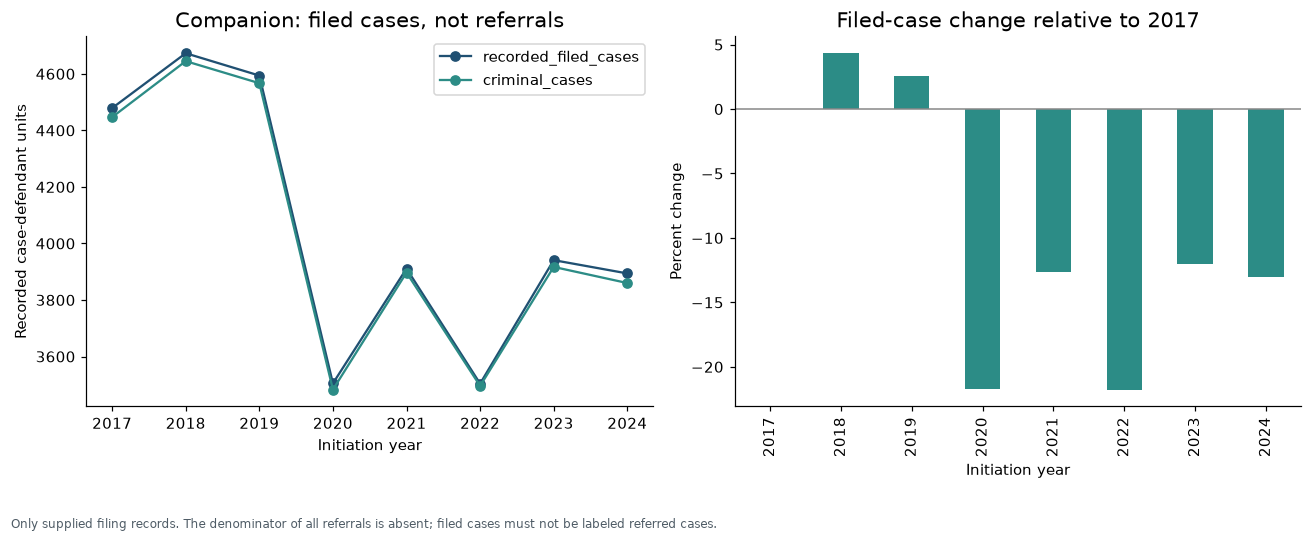

In [6]:
annual=fc.groupby('year').agg(recorded_filed_cases=('case_id','size'),criminal_cases=('any_criminal','sum'))
annual['change_yoy_pct']=annual.recorded_filed_cases.pct_change()*100
annual['change_from_2017_pct']=(annual.recorded_filed_cases/annual.loc[2017,'recorded_filed_cases']-1)*100
table('Q01_filed_case_companion',annual)
fig,axs=plt.subplots(1,2,figsize=(12,5))
annual[['recorded_filed_cases','criminal_cases']].plot(ax=axs[0],marker='o')
axs[0].set(title='Companion: filed cases, not referrals',ylabel='Recorded case-defendant units',xlabel='Initiation year')
annual.change_from_2017_pct.plot.bar(ax=axs[1],color=COLORS[1]);axs[1].axhline(0,color='#888',lw=1)
axs[1].set(title='Filed-case change relative to 2017',ylabel='Percent change',xlabel='Initiation year')
finish(fig,'Q01_filed_case_companion','Only supplied filing records. The denominator of all referrals is absent; filed cases must not be labeled referred cases.')
answer(1,'Not answerable',f'Referrals cannot be counted. Companion: {len(fc):,} recorded filed case-defendant units; filing volume changed {annual.loc[2024,"change_from_2017_pct"]:.1f}% from 2017 to 2024.',
 'No referral intake table or record of cases screened out before filing. Internal case-defendant unit needs a team docket rule.',
 'Case-defendant proxy','All supplied initiated cases, for the companion only')
contract(1,'Two-panel annual count and percent change','Case','Initiation year','Filed cases (companion only)','All supplied filed cases','Keep Unknown class', 'Referral intake records for literal Q1')

## Q2. What is the per-capita case rate (cases per 10,000 residents), so counties of different sizes can be compared?

**Scope: Volume and scope.** No population figures appear in the three Berkshire files. The user requested dataset-only analysis, so no population data are fetched, loaded, inferred, or hardcoded.

In [7]:
answer(2,'Not answerable','No per-capita rate is calculated.',
 'Annual county population estimates are absent. A flat or guessed denominator would not answer the question.',
 'Cases per 10,000 residents','Annual county resident population — unavailable')
contract(2,'Annual line chart once the denominator is supplied','Case / residents','2017–2024','Agreed annual case count','Annual county population','Do not impute','External annual population series; not used here')

## Q3. What share of cases are felonies vs. misdemeanors, and what are the 5 most common offense categories?

**Scope: Volume and scope.** Cases use their highest recorded source class. The datasets do not contain a validated broad offense-category crosswalk or statutory seriousness within a class. The top-five representative charge codes are shown as a labeled proxy, not as newly invented offense categories.

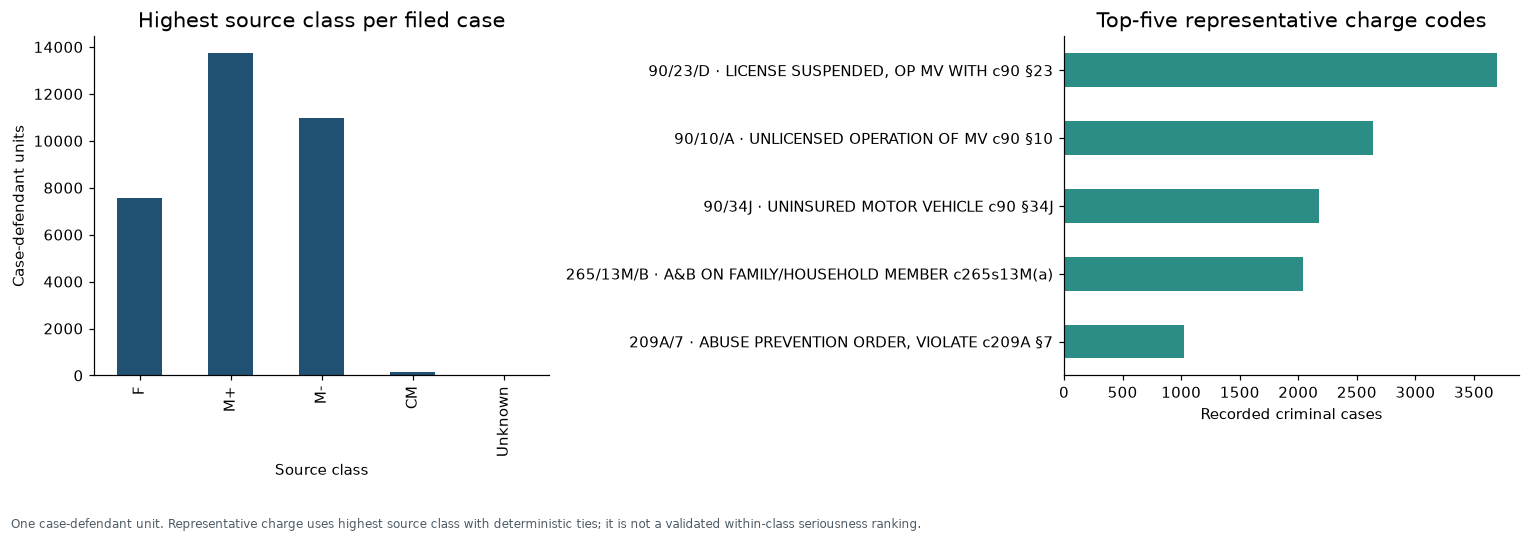

In [8]:
severity=fc.source_class.value_counts().reindex(['F','M+','M-','CM','Unknown'],fill_value=0).to_frame('cases')
severity['percent_all_filed_cases']=severity.cases/len(fc)*100
severity['percent_criminal_cases']=severity.cases.where(severity.index.isin(['F','M+','M-']))/len(fc_criminal)*100
table('Q03_case_severity',severity)
top5=fc_criminal.representative_code.value_counts().head(5)
table('Q03_top_five_representative_codes',top5.rename(index=labels).to_frame('criminal_cases'))
fig,axs=plt.subplots(1,2,figsize=(14,5))
severity.cases.plot.bar(ax=axs[0],color=COLORS[0]);axs[0].set(title='Highest source class per filed case',ylabel='Case-defendant units',xlabel='Source class')
top5.rename(index={c:labels.get(c,c)[:55] for c in top5.index}).sort_values().plot.barh(ax=axs[1],color=COLORS[1])
axs[1].set(title='Top-five representative charge codes',xlabel='Recorded criminal cases',ylabel='')
finish(fig,'Q03_severity_and_top_codes','One case-defendant unit. Representative charge uses highest source class with deterministic ties; it is not a validated within-class seriousness ranking.')
felony=fc_criminal.source_class.eq('F').mean()*100
answer(3,'Partial',f'{felony:.1f}% of recorded criminal filing cases have a felony as their highest source class; {100-felony:.1f}% have a misdemeanor. Top-five representative codes are tabulated.',
 'Broad offense categories and within-class statutory seriousness are unavailable. Civil/Unknown-only cases are excluded from the criminal percentage and shown separately.',
 'Case-defendant proxy','Cases with at least one F/M+/M− charge')
contract(3,'Class composition plus top-five horizontal bars','Case','Initiation year','Cases in highest-source-class / representative-code group','All criminal filed cases','Show CM and Unknown separately','Team offense-category crosswalk and seriousness rule')

## Q4. What percentage of referred cases does the prosecutor decline to charge?

**Scope: Charging decisions.** A dismissal or nolle prosequi after filing is not proof of a pre-filing declination. Do not substitute either for a referral-screening decision.

In [9]:
answer(4,'Not answerable','Declination rate is not measurable.',
 'Neither all referred cases nor pre-filing decline decisions are supplied. Post-filing outcomes cannot reconstruct this denominator.',
 'Referred case','All referred cases — unavailable')
contract(4,'Declined / charged / unknown bar once referral data exist','Referred case','Referral year','Documented pre-filing declinations','All referrals','Unknown screening decision retained','Referral intake and screening outcomes')

## Q5. How often is the filed charge different from the arrest/referral charge (upgraded, downgraded, unchanged)?

**Scope: Charging decisions.** This question is intentionally charge-level. A filing/disposition match does not provide the original arrest/referral charge or a complete amendment history.

In [10]:
answer(5,'Not answerable','Upgrade, downgrade, and unchanged rates are not calculated.',
 'No original arrest/referral-charge field, versioned amendments, or validated severity ordering is present. Same-code matches across two extracts do not prove the charge was never changed.',
 'Charge','All arrest/referral charges with linked filed charge — unavailable')
contract(5,'Three-category charge transition chart','Charge','Referral-to-filing interval','Upgraded/downgraded/unchanged linked charges','All charges with an original and filed version','Unknown transition retained','Original charges, amendment history, statutory ordering')

## Q6. What share of cases are diverted to alternative programs instead of prosecuted?

**Scope: Charging decisions.** The files contain CWOF and continuation labels, but no documented program enrollment/intake denominator. CWOF is not automatically relabeled as pre-prosecution diversion.

In [11]:
signal=disposed_clean[['disp_type','disp_description','sentence_translation']].astype('string').apply(
    lambda s:s.str.contains('diversion|pre.?trial probation',case=False,regex=True,na=False)).any(axis=1)
table('Q06_explicit_program_signal_audit',pd.Series({'disposed_rows_examined':len(disposed_clean),
 'rows_with_explicit_program_text_signal':int(signal.sum()),'program_enrollment_field_present':False},name='audit'))
answer(6,'Not answerable','A diversion-program participation rate cannot be established.',
 'No program enrollment, eligibility, intake, or completion field. Absence of explicit diversion text is not evidence of zero diversion. CWOF remains separate.',
 'Case','Cases eligible/referred for diversion or all charged cases, as agreed — unavailable')
contract(6,'Program participation chart after a definition is agreed','Case','2017–2024','Documented alternative-program cases','Agreed eligible/charged case population','CWOF separate; absence is not zero','Program enrollment and eligibility data')

## Q7. Of charged cases, what percentage end in dismissal, plea, trial conviction, or acquittal?

**Scope: Case outcomes.** The exact all-charged-case eventual outcome rate is not observed. This companion uses recorded closed criminal case-defendant units with latest observed disposition in 2017–2024. Each receives one provisional highest outcome, with CWOF and unresolved cases retained. Unknown share controls whether percentage claims are reportable.

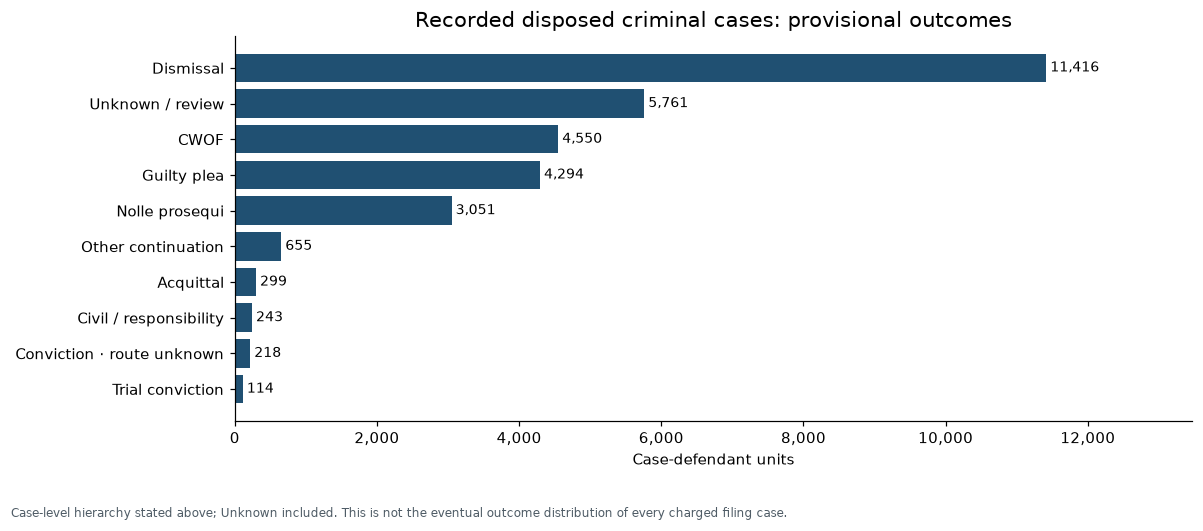

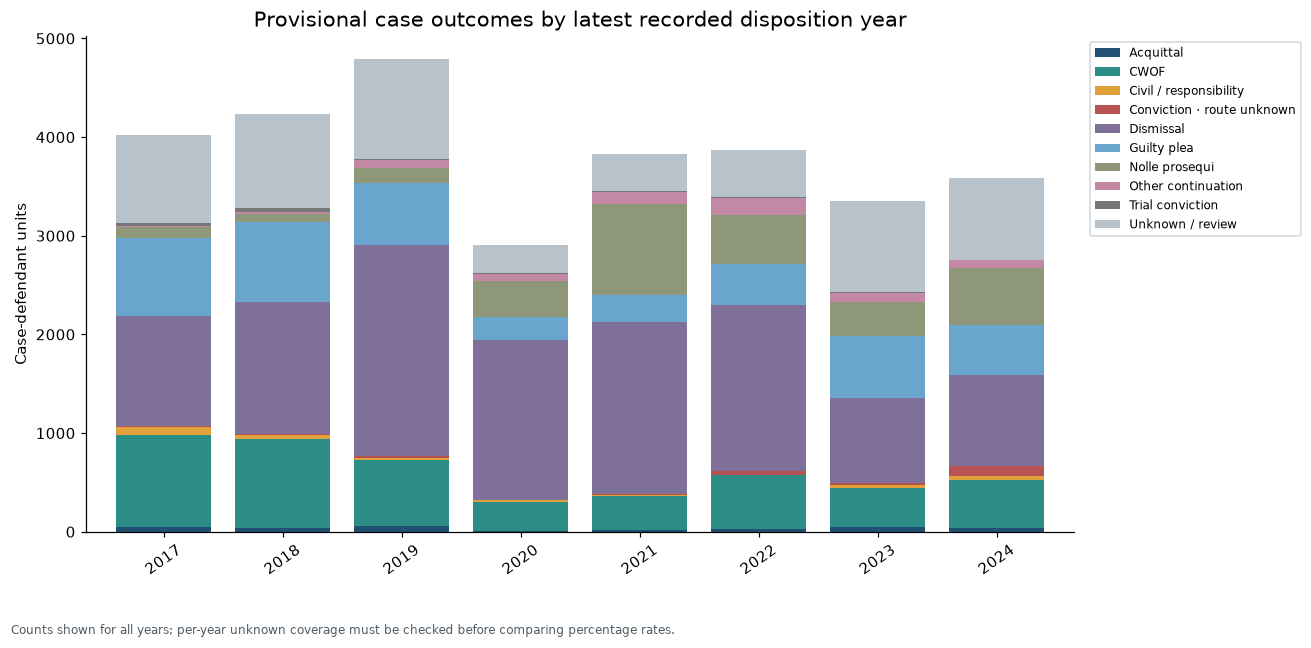

In [12]:
outcomes=dc.outcome.value_counts().reindex(['Trial conviction','Guilty plea','Conviction · route unknown','CWOF','Acquittal',
 'Nolle prosequi','Dismissal','Other continuation','Civil / responsibility','Unknown / review'],fill_value=0).to_frame('cases')
outcomes['percent_of_observed_disposed_cases']=outcomes.cases/len(dc)*100 if outcome_unknown_share<=.2 else np.nan
table('Q07_case_outcome_distribution',outcomes)
by_year=pd.crosstab(dc.year,dc.outcome)
table('Q07_case_outcome_by_disposition_year',by_year)
fig,ax=barh(outcomes.cases,'Recorded disposed criminal cases: provisional outcomes','Case-defendant units')
finish(fig,'Q07_case_outcome_counts','Case-level hierarchy stated above; Unknown included. This is not the eventual outcome distribution of every charged filing case.')
fig,ax=stacked(by_year,'Provisional case outcomes by latest recorded disposition year',percent=False)
ax.set_ylabel('Case-defendant units')
finish(fig,'Q07_case_outcomes_annual','Counts shown for all years; per-year unknown coverage must be checked before comparing percentage rates.')
unknown_year=dc.groupby('year').outcome_unknown.agg(cases='size',unknown_cases='sum')
unknown_year['unknown_pct']=unknown_year.unknown_cases/unknown_year.cases*100
table('Q07_outcome_coverage_by_year',unknown_year)
answer(7,'Partial',f'{len(dc):,} observed closed criminal case units can be summarized; {outcome_unknown_share:.1%} require outcome review. '+
 ('Overall provisional shares are shown with Unknown retained.' if outcome_unknown_share<=.2 else 'Outcome unknowns exceed 20%, so dependent overall percentage claims are withheld.'),
 'No complete eventual-outcome history for all charged cases; the case hierarchy and docket rule require team agreement. Diversion participation is not identified.',
 'Case-defendant proxy','Observed closed criminal case units with latest recorded disposition in 2017–2024')
contract(7,'Outcome count/share stacked bars with Unknown','Case','Latest recorded disposition year','Cases assigned each agreed highest outcome','Observed disposed criminal cases','Unknown retained; withhold rates above 20%','Client-approved crosswalk and docket/case closure definition')

## Q8. What is the plea rate, and how often do pleas involve a reduced charge?

**Scope: Case outcomes.** An observed Plea label can be counted once per case, but it does not establish a guilty finding or a reduced charge. The denominator below is the observed disposed-case population, not every charged case.

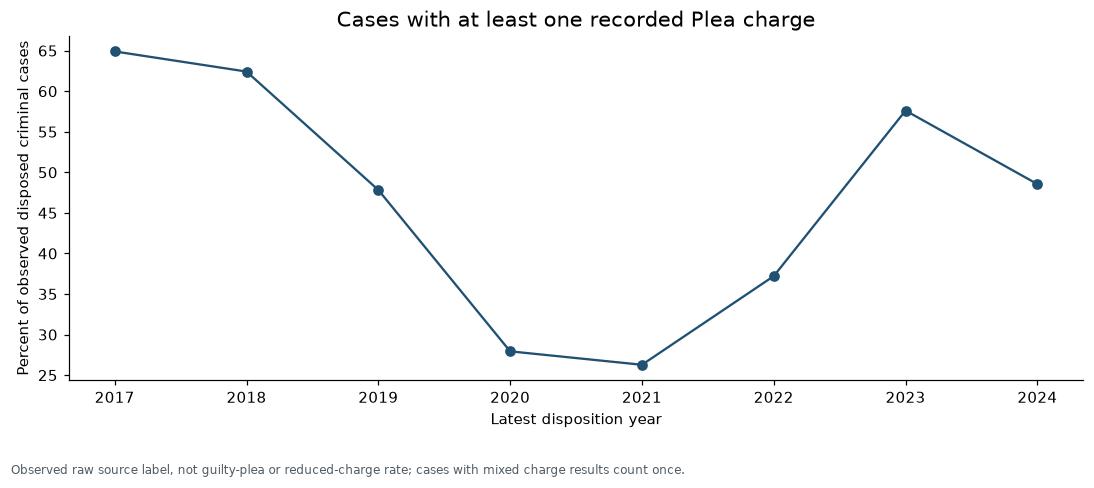

In [13]:
plea_cases=dc.any_plea_label.sum()
plea_year=dc.groupby('year').any_plea_label.agg(cases='size',cases_with_plea_label='sum')
plea_year['observed_case_plea_label_pct']=plea_year.cases_with_plea_label/plea_year.cases*100
table('Q08_recorded_plea_label_by_case',plea_year)
fig,ax=plt.subplots(figsize=(10,4.5));ax.plot(plea_year.index,plea_year.observed_case_plea_label_pct,marker='o')
ax.set(title='Cases with at least one recorded Plea charge',xlabel='Latest disposition year',ylabel='Percent of observed disposed criminal cases')
finish(fig,'Q08_recorded_plea_label','Observed raw source label, not guilty-plea or reduced-charge rate; cases with mixed charge results count once.')
answer(8,'Partial',f'{plea_cases:,} of {len(dc):,} observed disposed criminal case units ({plea_cases/len(dc):.1%}) have at least one Plea label.',
 'Original charges and plea agreements are absent, so reduced-charge frequency is not measurable. Plea includes CWOF and unresolved sentence results.',
 'Case-defendant proxy','Observed disposed criminal cases for the Plea-label companion')
contract(8,'Annual observed Plea-label line; reduced-charge component withheld','Case','Disposition year','Cases with ≥1 Plea label','Observed disposed criminal cases','Do not infer conviction from Plea','Original charge versions and plea agreement data for reductions')

## Q9. What share of cases go to trial, and what is the conviction rate at trial?

**Scope: Case outcomes.** Only explicit Trial labels are used. Guilty/Not Guilty labels with no known route are not assumed to be trial outcomes. The all-charged-case trial participation rate is unavailable; the observed disposed-case companion is shown. Trial-result rates are withheld if more than 20% of explicit trial cases have unresolved results.

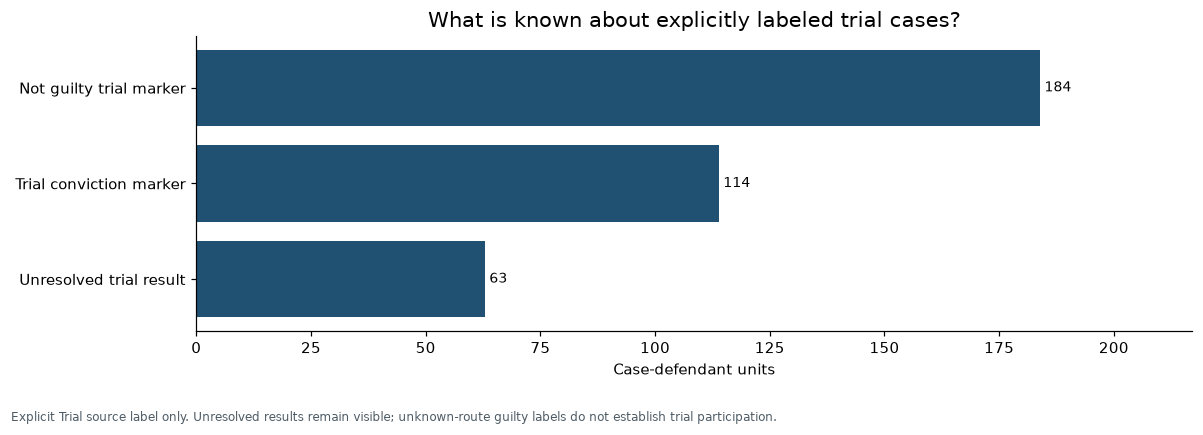

In [14]:
trial_rows=criminal_rows.loc[criminal_rows.disp_type.eq('Trial')]
trial_results=trial_rows.groupby('case_person').detail.agg(lambda s:
 'Trial conviction marker' if s.eq('Trial · guilty marker').any() else
 'Unresolved trial result' if s.eq('Trial · result unresolved').any() else
 'Not guilty trial marker' if s.eq('Trial · not guilty marker').all() else 'Unresolved trial result')
tc=dc.loc[dc.any_trial_label].copy();tc['trial_result']=trial_results.reindex(tc.index)
trial_unknown=tc.trial_result.eq('Unresolved trial result').mean()
trial_counts=tc.trial_result.value_counts().to_frame('cases')
trial_counts['percent_explicit_trial_cases']=trial_counts.cases/len(tc)*100 if trial_unknown<=.2 else np.nan
table('Q09_explicit_trial_case_results',trial_counts)
fig,ax=barh(trial_counts.cases,'What is known about explicitly labeled trial cases?','Case-defendant units')
finish(fig,'Q09_trial_result_coverage','Explicit Trial source label only. Unresolved results remain visible; unknown-route guilty labels do not establish trial participation.')
answer(9,'Partial',f'{len(tc):,} observed disposed criminal case units ({len(tc)/len(dc):.1%}) have an explicit Trial label; {trial_unknown:.1%} of those trial results are unresolved. '+
 ('The trial-conviction marker share is reportable for this explicit-label subset.' if trial_unknown<=.2 else 'The trial-result unknown share exceeds 20%; no conviction-rate claim is reported.'),
 'Trial labels may not capture every trial; all-charged cases and unknown-route results prevent the literal full-population estimate.',
 'Case-defendant proxy','Explicitly Trial-labeled cases, for result completeness')
contract(9,'Trial-result counts with unresolved category','Case','Disposition year','Explicit trial conviction/not-guilty markers','Explicitly Trial-labeled cases','No rate if unresolved >20%','Complete trial event and verdict records for literal question')

## Q10. What share of convictions result in incarceration vs. probation vs. fines/other?

**Scope: Sentencing.** A source-indicated conviction requires an unambiguous conviction marker in at least one criminal charge. Sentence type is rolled up once per case: incarceration first, then probation/suspended, then fines/other; unresolved conviction-charge sentences remain Unknown. Custody is a source sentence translation, not a prison-admission or time-served record.

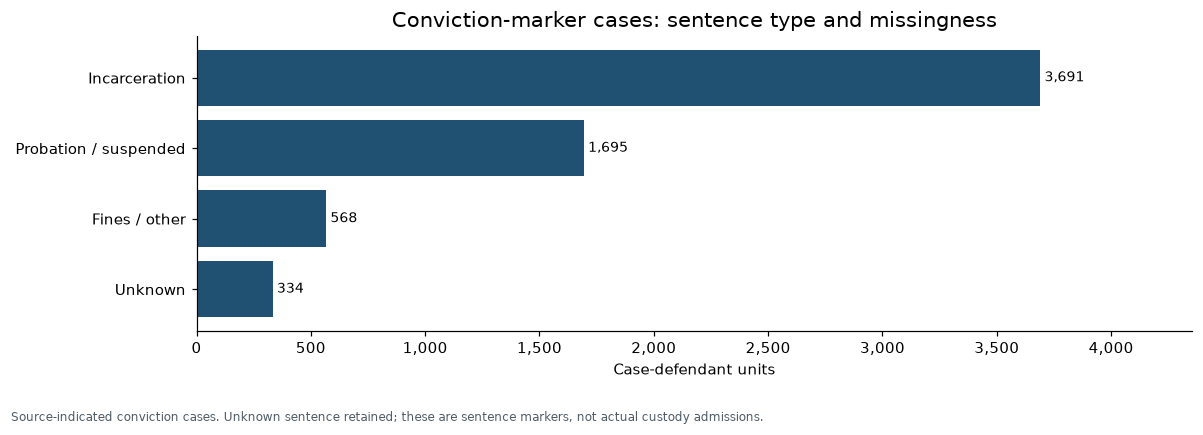

In [15]:
sentence_counts=conv.sentence_type.value_counts().reindex(['Incarceration','Probation / suspended','Fines / other','Unknown'],fill_value=0).to_frame('cases')
sentence_counts['percent_of_source_indicated_conviction_cases']=sentence_counts.cases/len(conv)*100 if sentence_unknown_share<=.2 else np.nan
table('Q10_sentence_type_and_coverage',sentence_counts)
fig,ax=barh(sentence_counts.cases,'Conviction-marker cases: sentence type and missingness','Case-defendant units')
finish(fig,'Q10_sentence_type_coverage','Source-indicated conviction cases. Unknown sentence retained; these are sentence markers, not actual custody admissions.')
answer(10,'Partial' if sentence_unknown_share<=.2 else 'Insufficient data',
 f'{len(conv):,} cases have a source-indicated conviction; sentence type is unresolved for {sentence_unknown_share:.1%}. '+
 ('Conditional sentence-type shares are tabulated, including Unknown.' if sentence_unknown_share<=.2 else 'The missingness threshold fails, so incarceration/probation/fine percentage claims are withheld.'),
 'Conviction and sentence crosswalks remain provisional. Actual imprisonment/time served is not provided; incomplete conviction classification can select the denominator.',
 'Case-defendant proxy','Cases with at least one unambiguous source-indicated conviction')
contract(10,'Sentence type plus Unknown bar','Convicted case','Disposition year','Cases by most severe recorded sentence type','Source-indicated conviction cases','Unknown retained; >20% means insufficient','Validated conviction/sentence fields and case sentence linkage')

## Q11. What is the median sentence length by offense category?

**Scope: Sentencing.** The source has term values and units, but no validated broad offense categories or total case sentence accounting for concurrent/consecutive counts. A bounded companion estimates the longest recorded actual jail maximum term among explicit custodial conviction charges in a case. It is not the total sentence or time served. Missingness is checked within the custodial-case population.

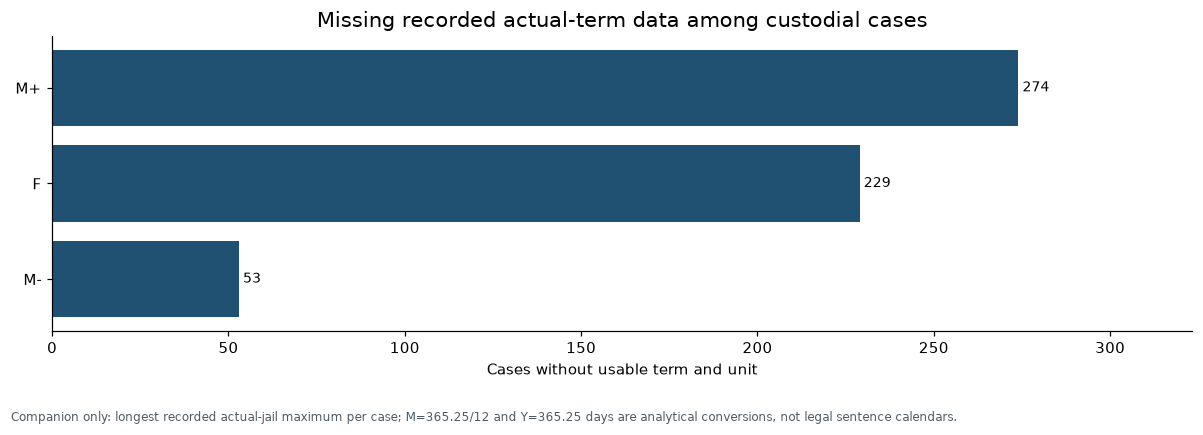

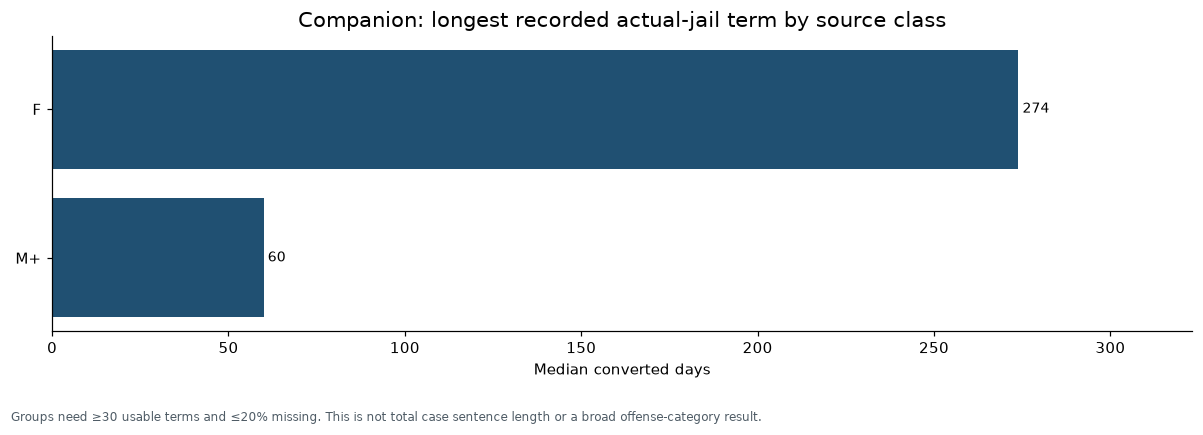

In [16]:
unit_days={'D':1,'W':7,'M':365.25/12,'Y':365.25,'H':1/24}
custodial=criminal_rows.loc[criminal_rows.conviction_marker&criminal_rows.sentence_type.eq('Incarceration')].copy()
custodial['term_value']=pd.to_numeric(custodial['Max Actl Jail Imp Term'],errors='coerce')
custodial['unit_days']=custodial['Max Actl Jail Imp Unt'].map(unit_days)
custodial['actual_max_days']=(custodial.term_value*custodial.unit_days).where(custodial.term_value.ge(0))
duration_case=custodial.groupby('case_person').actual_max_days.max()
cc=conv.loc[conv.sentence_type.eq('Incarceration')].copy();cc['recorded_max_actual_days']=duration_case.reindex(cc.index)
duration_missing=cc.recorded_max_actual_days.isna().mean()
duration_summary=cc.groupby('source_class').agg(custodial_cases=('case_id','size'),usable_terms=('recorded_max_actual_days','count'),
 median_days_available=('recorded_max_actual_days','median'))
duration_summary['missing_pct']=(1-duration_summary.usable_terms/duration_summary.custodial_cases)*100
duration_summary['reportable_median_days']=duration_summary.median_days_available.where(
 (duration_summary.missing_pct<=20)&(duration_summary.usable_terms>=MIN_CELL))
table('Q11_recorded_actual_term_companion',duration_summary)
fig,ax=barh((duration_summary.custodial_cases-duration_summary.usable_terms),
 'Missing recorded actual-term data among custodial cases','Cases without usable term and unit')
finish(fig,'Q11_sentence_duration_coverage','Companion only: longest recorded actual-jail maximum per case; M=365.25/12 and Y=365.25 days are analytical conversions, not legal sentence calendars.')
eligible_medians=duration_summary.reportable_median_days.dropna()
if len(eligible_medians):
    fig,ax=barh(eligible_medians,'Companion: longest recorded actual-jail term by source class','Median converted days')
    finish(fig,'Q11_recorded_term_medians','Groups need ≥30 usable terms and ≤20% missing. This is not total case sentence length or a broad offense-category result.')
answer(11,'Partial',f'Total case sentence length by offense category is not identifiable. For the limited explicit-custody term companion, {duration_missing:.1%} of cases lack usable maximum actual-term data.',
 'No total concurrent/consecutive case sentence, complete term history, or broad offense-category mapping. Available terms cannot be treated as time served.',
 'Custodial case proxy','Explicit custodial conviction-marker cases, for coverage diagnostics only')
contract(11,'Duration coverage bar; median only for reportable groups','Custodial case','Disposition year','Longest recorded actual jail maximum term','Custodial cases with term coverage audited','>20% missing withholds median','Total sentence structure and agreed offense categories')

## Q12. What share of defendants are detained pretrial, and how often is cash bail set?

**Scope: Pretrial and timing.** The bail file has case IDs but no person ID or custody-duration/payment ledger. Select the first valid observed event within 2017–2024, not a guaranteed initial arraignment. Link only case IDs that correspond to one defendant in the full filing extract. County-wide defendant detention and cash-bail rates are not inferred from incomplete bail coverage.

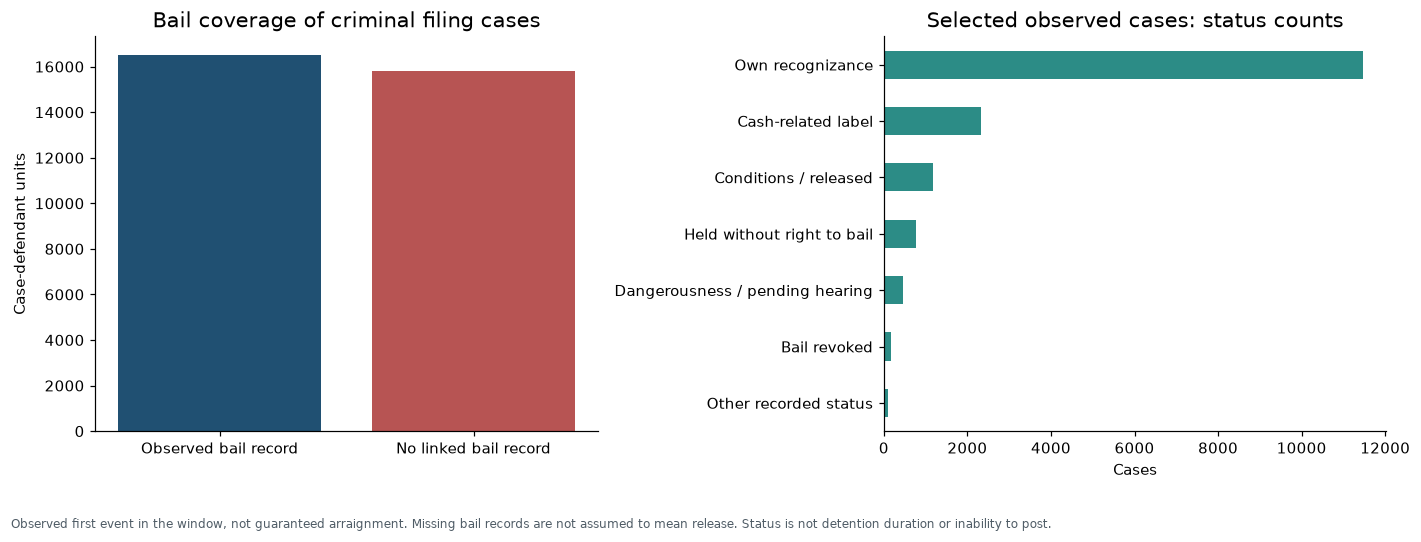

In [17]:
b['bail_status']=b.bail_status.fillna('Missing').replace({'Out On Cash Bail':'Out on Cash Bail'})
cash_labels=['Cash Only','Cash/Surety','In Custody - Bail Set','Out on Cash Bail']
b['cash_label']=b.bail_status.isin(cash_labels)
def bail_group(s):
    if s=='Released on Own Recognizance':return 'Own recognizance'
    if s in cash_labels:return 'Cash-related label'
    if s=='Held Without Right To Bail':return 'Held without right to bail'
    if s in ['Held Pending DH','Held as a Danger']:return 'Dangerousness / pending hearing'
    if s=='Bail Revoked':return 'Bail revoked'
    if s=='Conditions Only' or 'released w/conditions' in s:return 'Conditions / released'
    return 'Other recorded status'
b['status_group']=b.bail_status.map(bail_group)
first=b.sort_values(['bail_date','bail_status','source_row']).drop_duplicates('case_id')
person_counts=filed_clean.groupby('case_id').person_id.nunique()
single=person_counts.loc[person_counts==1].index
case_identity=filed_clean.loc[filed_clean.case_id.isin(single),['case_id','case_person']].drop_duplicates()
assert not case_identity.case_id.duplicated().any()
bf=first.merge(case_identity,on='case_id',how='inner',validate='one_to_one')
bf=bf.loc[bf.case_person.isin(fc_criminal.index)].copy()
bail_missing=1-len(bf)/len(fc_criminal)
status_counts=bf.status_group.value_counts().to_frame('observed_criminal_filing_cases')
table('Q12_bail_coverage',pd.Series({'criminal_filing_cases':len(fc_criminal),
 'with_one_linked_first_observed_bail_event':len(bf),'without_linked_event':len(fc_criminal)-len(bf),
 'without_linked_event_pct':bail_missing*100},name='count_or_pct'))
table('Q12_selected_bail_status_counts',status_counts)
fig,axs=plt.subplots(1,2,figsize=(13,5))
axs[0].bar(['Observed bail record','No linked bail record'],[len(bf),len(fc_criminal)-len(bf)],color=[COLORS[0],COLORS[3]])
axs[0].set(title='Bail coverage of criminal filing cases',ylabel='Case-defendant units')
status_counts.iloc[:,0].sort_values().plot.barh(ax=axs[1],color=COLORS[1]);axs[1].set(title='Selected observed cases: status counts',xlabel='Cases',ylabel='')
finish(fig,'Q12_bail_coverage_and_status','Observed first event in the window, not guaranteed arraignment. Missing bail records are not assumed to mean release. Status is not detention duration or inability to post.')
answer(12,'Partial',f'Bail records link to {len(bf):,} of {len(fc_criminal):,} criminal filing case units; {bail_missing:.1%} have no linked first observed event. Selected status counts are shown.',
 'No complete defendant bail/custody history, ability-to-pay indicator, or payment/posting ledger. County-wide detention/cash-bail rates are withheld when coverage fails the 20% rule.',
 'Linked case, not unique defendant','All criminal filing cases for coverage; observed cases for status counts')
contract(12,'Bail coverage bar plus observed-status counts','Case proxy','First valid event in study window','Observed recorded status labels','All criminal filed cases for coverage','No bail record ≠ released','Complete arraignment/custody/payment history and defendant link')

## Q13. What is the median time from filing to disposition, and does it differ by case type?

**Scope: Pretrial and timing.** Use one interval per observed disposed criminal case: latest recorded disposition minus earliest recorded initiation. Negative/missing intervals are excluded and counted. Source initiation is a filing proxy. Case type is not supplied in the charges files; source class, representative charge code, and court provide labeled partial breakdowns.

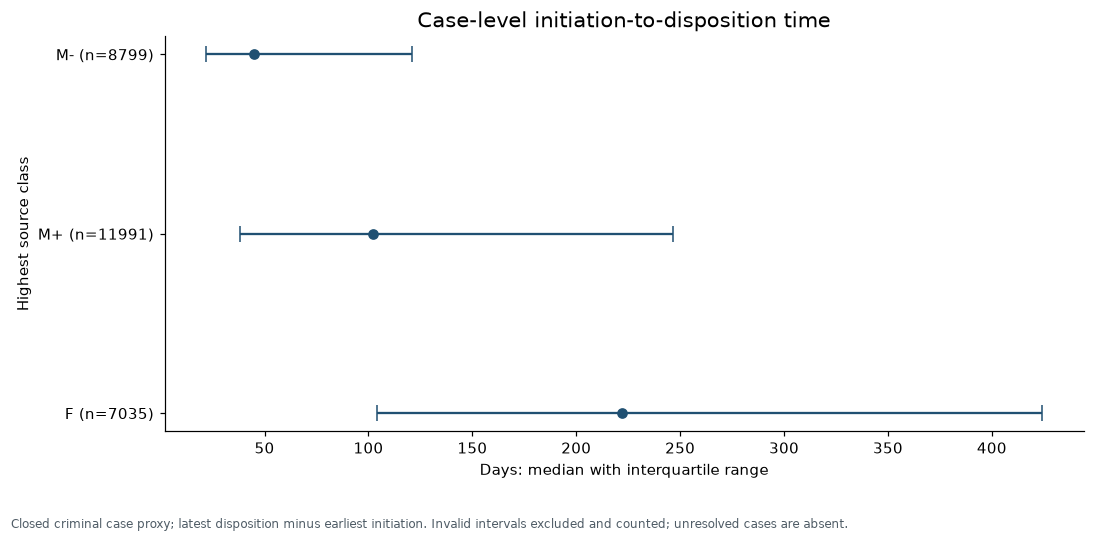

In [18]:
duration=dc.loc[dc.filing_to_disposition_days.ge(0)].copy()
invalid_count=len(dc)-len(duration)
duration_groups=duration.groupby('source_class').filing_to_disposition_days.agg(cases='size',median='median',
 p25=lambda s:s.quantile(.25),p75=lambda s:s.quantile(.75))
table('Q13_case_processing_time',duration.filing_to_disposition_days.describe(percentiles=[.25,.5,.75]).to_frame('days'))
table('Q13_processing_time_by_class',duration_groups)
court_duration=duration.groupby('court').filing_to_disposition_days.agg(cases='size',median='median',
 p25=lambda s:s.quantile(.25),p75=lambda s:s.quantile(.75))
table('Q13_processing_time_by_court',court_duration)
fig,ax=plt.subplots(figsize=(10,5))
groups=duration_groups.loc[duration_groups.cases>=MIN_CELL]
ax.errorbar(groups['median'],range(len(groups)),xerr=[groups['median']-groups.p25,groups.p75-groups['median']],fmt='o',capsize=5)
ax.set_yticks(range(len(groups)),[f'{c} (n={n})' for c,n in zip(groups.index,groups.cases)])
ax.set(title='Case-level initiation-to-disposition time',xlabel='Days: median with interquartile range',ylabel='Highest source class')
finish(fig,'Q13_case_processing_time','Closed criminal case proxy; latest disposition minus earliest initiation. Invalid intervals excluded and counted; unresolved cases are absent.')
answer(13,'Partial',f'Median {duration.filing_to_disposition_days.median():,.0f} days; IQR {duration.filing_to_disposition_days.quantile(.25):,.0f}–{duration.filing_to_disposition_days.quantile(.75):,.0f}, among {len(duration):,} usable case intervals. {invalid_count:,} cases have invalid/missing intervals.',
 'Initiation is not independently verified as filing date. No complete case-type field in charge files. Disposed-case selection and older/recent cohort differences prevent an all-filed-case expected duration.',
 'Case-defendant proxy','Observed disposed criminal cases with valid nonnegative interval')
contract(13,'Median/IQR dot plot by source class and court','Case','Latest recorded disposition year','Latest disposition minus earliest initiation','Cases with usable interval; invalid share reported','Exclude negative/missing; report exclusions','Verified filing-date semantics and case-type definition')

## Q14. Do declination, dismissal, and incarceration rates differ by defendant race/ethnicity?

**Scope: Equity.** Race is recorded in one administrative field; a separate ethnicity measure is absent. Dismissal/nolle is an exclusive provisional case outcome among observed disposed cases. Incarceration is among source-indicated conviction cases. Per-group denominators, missingness, and a White reference ratio are shown. These are descriptive associations; unknown outcome coverage can withhold a group’s rate.

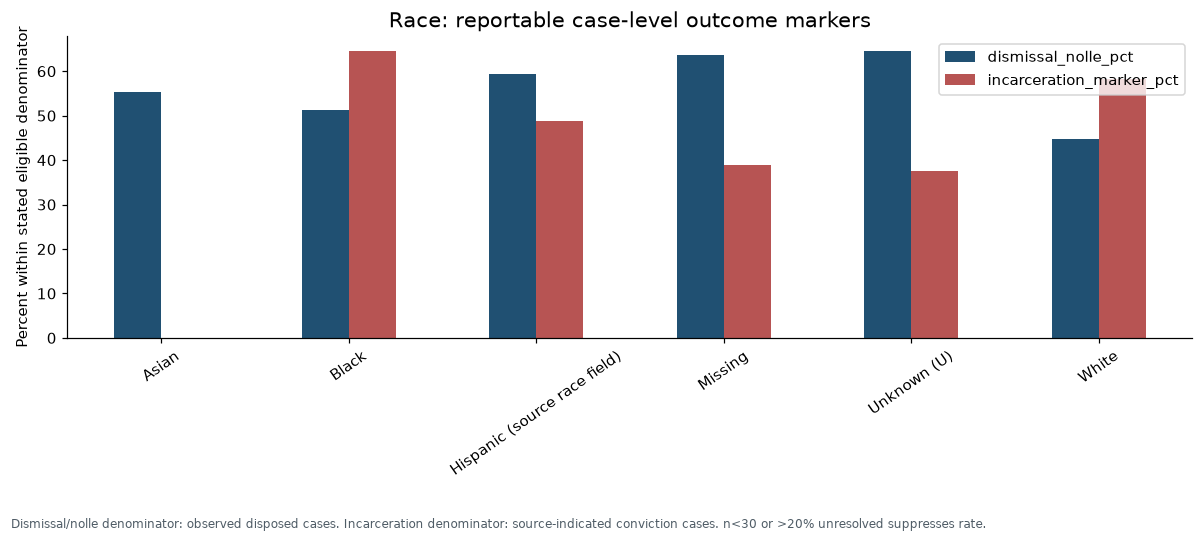

In [19]:
def equity_table(group):
    rows=[]
    for label,g in dc.groupby(group):
        vg=conv.loc[conv.index.intersection(g.index)]
        unknown_outcome=g.outcome_unknown.mean()
        unknown_sentence=vg.sentence_type.eq('Unknown').mean() if len(vg) else np.nan
        dismissal=g.outcome.isin(['Dismissal','Nolle prosequi']).mean()
        incarceration=vg.sentence_type.eq('Incarceration').mean() if len(vg) else np.nan
        rows.append({'group':label,'disposed_cases':len(g),'outcome_unknown_pct':unknown_outcome*100,
          'dismissal_nolle_pct':dismissal*100 if len(g)>=MIN_CELL and unknown_outcome<=.2 else np.nan,
          'conviction_marker_cases':len(vg),'sentence_unknown_pct':unknown_sentence*100,
          'incarceration_marker_pct':incarceration*100 if len(vg)>=MIN_CELL and unknown_sentence<=.2 else np.nan})
    result=pd.DataFrame(rows).set_index('group')
    reference='White' if group=='race' else 'Male'
    for metric in ['dismissal_nolle_pct','incarceration_marker_pct']:
        baseline=result.loc[reference,metric] if reference in result.index else np.nan
        result[metric+'_ratio_vs_'+reference]=result[metric]/baseline if pd.notna(baseline) and baseline>0 else np.nan
    return result
race_equity=equity_table('race')
table('Q14_case_outcomes_by_race',race_equity,rows=30)
fig,ax=plt.subplots(figsize=(11,5))
plot=race_equity[['dismissal_nolle_pct','incarceration_marker_pct']].dropna(how='all')
plot.plot.bar(ax=ax,color=[COLORS[0],COLORS[3]]);ax.set(title='Race: reportable case-level outcome markers',ylabel='Percent within stated eligible denominator',xlabel='')
ax.tick_params(axis='x',rotation=35)
finish(fig,'Q14_case_outcome_markers_by_race','Dismissal/nolle denominator: observed disposed cases. Incarceration denominator: source-indicated conviction cases. n<30 or >20% unresolved suppresses rate.')
answer(14,'Partial','Reportable dismissal/nolle and recorded-incarceration marker comparisons, with White reference ratios, are tabulated; declination is unavailable.',
 'No referral screening, separate ethnicity measure, population exposure, prior record, or complete case facts. Denominators differ by metric; these are not causal or population-adjusted disparities.',
 'Case-defendant proxy','Disposed cases for dismissal; conviction-marker cases for incarceration')
contract(14,'Two outcome-marker panels with White reference ratios','Case','Disposition year','Dismissal/nolle or recorded-incarceration cases','Eligible case population specified separately','Unknown group retained; per-group >20% gate','Referral/ethnicity/prior-record data for full question')

## Q15. Do those outcomes differ by sex and age group?

**Scope: Equity.** Use recorded sex, not inferred gender identity. No age or date of birth exists in the supplied columns. The sex comparison uses exactly the same case-level outcomes and coverage rules as Q14.

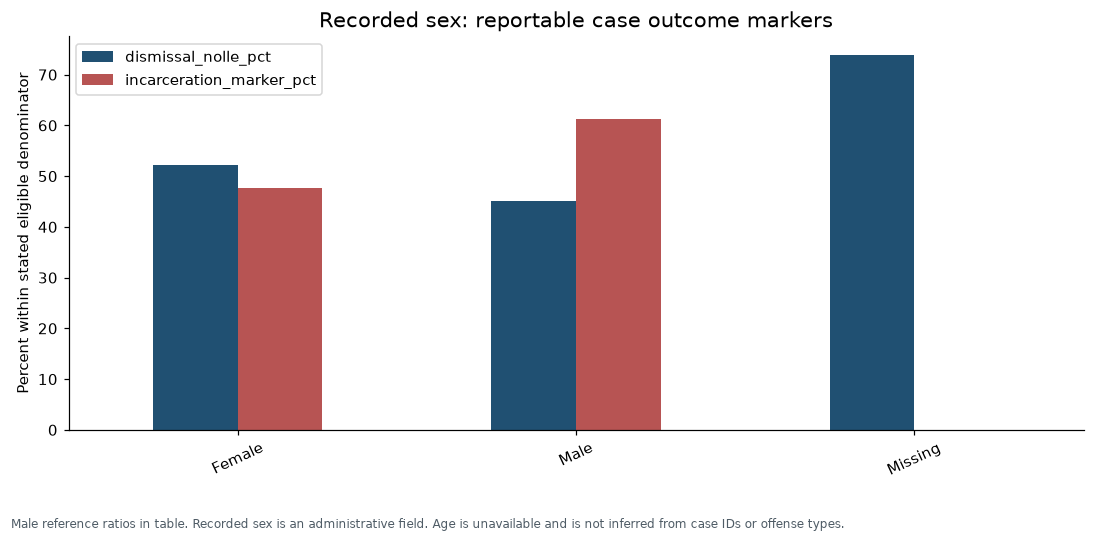

In [20]:
sex_equity=equity_table('sex')
table('Q15_case_outcomes_by_recorded_sex',sex_equity,rows=30)
fig,ax=plt.subplots(figsize=(10,5))
sex_equity[['dismissal_nolle_pct','incarceration_marker_pct']].dropna(how='all').plot.bar(ax=ax,color=[COLORS[0],COLORS[3]])
ax.set(title='Recorded sex: reportable case outcome markers',ylabel='Percent within stated eligible denominator',xlabel='');ax.tick_params(axis='x',rotation=25)
finish(fig,'Q15_case_outcomes_by_sex','Male reference ratios in table. Recorded sex is an administrative field. Age is unavailable and is not inferred from case IDs or offense types.')
answer(15,'Partial','Recorded-sex comparisons and Male reference ratios are available for reportable cells. Age-group results are not measurable.',
 'No age/date of birth; declination unavailable; administrative sex categories are not complete gender identity. All Q14 outcome and missingness limits also apply.',
 'Case-defendant proxy','As Q14, separately by recorded sex')
contract(15,'Same outcome-marker panels by recorded sex','Case','Disposition year','As Q14','As Q14','Unknown retained; suppress small/unresolved groups','Age/date of birth and referral data')

## Q16. Do racial disparities remain when you compare within the same offense category and prior-record level?

**Scope: Equity.** The dataset begins with a limited extraction window and does not supply a prior-record measure. Counting earlier rows in this extract would omit older and out-of-county history and would not provide the team’s uniform prior-record lookback.

In [21]:
answer(16,'Not answerable','The requested offense-by-prior-record controlled comparison cannot be performed.',
 'No validated prior record or uniform lookback, complete offense-category mapping, or full criminal history. Same-source-class comparisons alone would not answer this question.',
 'Case','Offense-category × prior-record cells — unavailable')
contract(16,'Within-category/prior-record rates or controlled model','Case','Common lookback and outcome period','Group outcomes in matched cells','Cases within offense × prior-record cells','Suppress cells below 30; unknown controls explicit','Prior-record measure with common lookback and category map')

## Q17. Did any of the above metrics shift noticeably around a policy change, new DA term, or 2020?

**Scope: Trends and context.** The date 2020 is in the question, so a descriptive comparison can be calculated without external context. No policy dates or DA-term dates are supplied. Changes cannot be attributed to COVID, a policy, or an officeholder from these data alone.

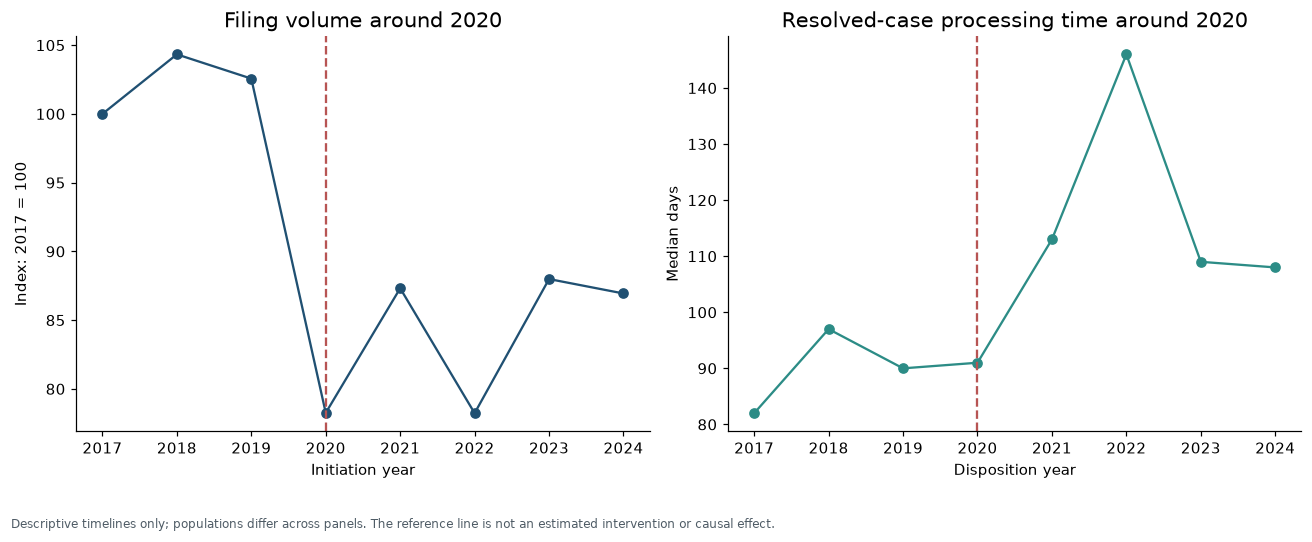

In [22]:
trend=annual.copy();trend['filed_case_index_2017_100']=trend.recorded_filed_cases/trend.loc[2017,'recorded_filed_cases']*100
timing_year=duration.groupby('year').filing_to_disposition_days.median()
trend['median_case_processing_days']=timing_year
table('Q17_descriptive_2020_trends',trend)
fig,axs=plt.subplots(1,2,figsize=(12,5))
axs[0].plot(trend.index,trend.filed_case_index_2017_100,marker='o');axs[0].axvline(2020,color=COLORS[3],ls='--')
axs[0].set(title='Filing volume around 2020',ylabel='Index: 2017 = 100',xlabel='Initiation year')
axs[1].plot(timing_year.index,timing_year,marker='o',color=COLORS[1]);axs[1].axvline(2020,color=COLORS[3],ls='--')
axs[1].set(title='Resolved-case processing time around 2020',ylabel='Median days',xlabel='Disposition year')
finish(fig,'Q17_descriptive_2020_trends','Descriptive timelines only; populations differ across panels. The reference line is not an estimated intervention or causal effect.')
change=(annual.loc[2020,'recorded_filed_cases']/annual.loc[2019,'recorded_filed_cases']-1)*100
answer(17,'Partial',f'Recorded filing case volume changed {change:.1f}% from 2019 to 2020. Time trends are shown without causal attribution.',
 'No policy/DA-term timeline or counterfactual. Data alone do not identify why a change occurred.',
 'Case-defendant proxy','Annual cases in each explicitly labeled population')
contract(17,'Indexed filing trend and median-time panel','Case','2017–2024','Annual recorded metrics','2017 baseline or annual eligible cases','Keep coverage visible','Policy/DA-term dates and causal design for attribution')

## Q18. How does this county rank against the state average and the other counties on the team’s core metrics (rates from Q4, Q7, Q10, Q14)?

**Scope: Trends and context.** This notebook is Berkshire-only. No other-county or statewide figures are imported, and a statewide average is not constructed from one county.

In [23]:
answer(18,'Not answerable','No statewide or inter-county ranking is calculated.',
 'Other-county datasets, common denominators, validated crosswalks, and comparable case units are absent. Berkshire declination is itself unmeasurable.',
 'County','Comparable eligible cases across all comparison counties — unavailable')
contract(18,'County dot plot only after harmonization','County','Same period in every county','Commonly defined eligible outcomes','Common case and denominator contract','Do not rank incomparable or missing counties','Other-county/statewide data; not used here')

## Q19. How does the number of recorded charges per case relate to the time from offense to disposition?

**Scope: Case complexity.** Aggregate before linking, so a case with many charges does not multiply its interval. Charge burden is the number of distinct recorded count/code tokens in the filing case; exact repeated exports are removed. Use only observed closed dispositions by 2024 and nonnegative offense-to-disposition intervals. The result is selected-case association, not a causal effect or a duration forecast for pending cases.

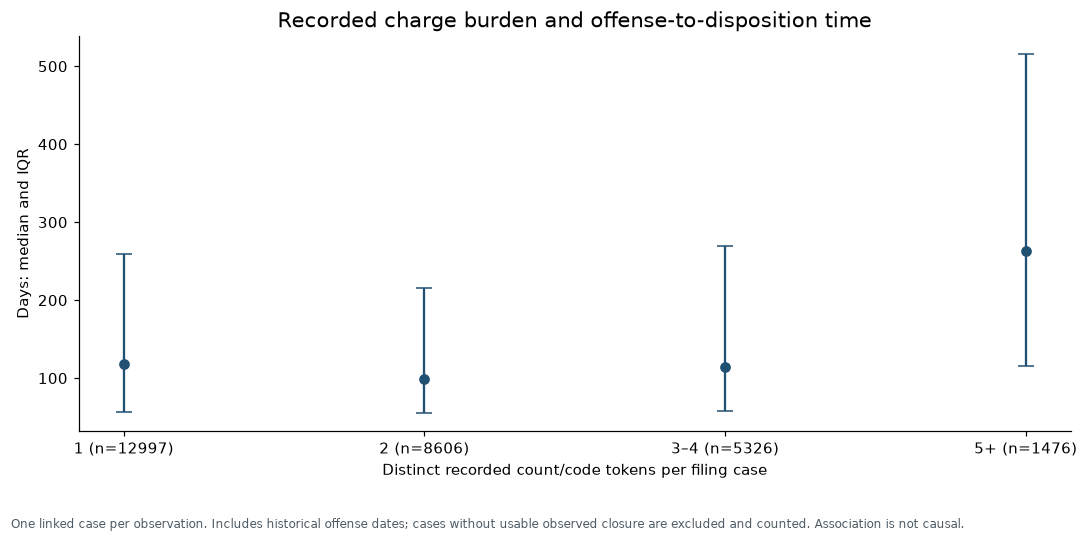

In [24]:
complexity=fc_criminal[['recorded_charge_tokens','representative_code','source_class']].merge(
 dc[['last_disposition','offense_date','offense_to_disposition_days']],left_index=True,right_index=True,how='inner',validate='one_to_one')
bad_complexity=complexity.offense_to_disposition_days.isna()|complexity.offense_to_disposition_days.lt(0)
valid_complexity=complexity.loc[~bad_complexity].copy()
valid_complexity['charge_burden']=pd.cut(valid_complexity.recorded_charge_tokens,[0,1,2,4,np.inf],labels=['1','2','3–4','5+'])
complexity_summary=valid_complexity.groupby('charge_burden',observed=True).offense_to_disposition_days.agg(cases='size',median='median',
 p25=lambda s:s.quantile(.25),p75=lambda s:s.quantile(.75))
table('Q19_charge_burden_and_time',complexity_summary)
table('Q19_linkage_and_interval_coverage',pd.Series({'criminal_filing_cases':len(fc_criminal),'linked_observed_closed_cases':len(complexity),
 'invalid_or_missing_interval_cases':int(bad_complexity.sum()),'usable_cases':len(valid_complexity)},name='cases'))
fig,ax=plt.subplots(figsize=(10,5));g=complexity_summary.loc[complexity_summary.cases>=MIN_CELL]
ax.errorbar(range(len(g)),g['median'],yerr=[g['median']-g.p25,g.p75-g['median']],fmt='o',capsize=5)
ax.set_xticks(range(len(g)),[f'{label} (n={n})' for label,n in zip(g.index,g.cases)])
ax.set(title='Recorded charge burden and offense-to-disposition time',xlabel='Distinct recorded count/code tokens per filing case',ylabel='Days: median and IQR')
finish(fig,'Q19_case_complexity','One linked case per observation. Includes historical offense dates; cases without usable observed closure are excluded and counted. Association is not causal.')
answer(19,'Partial',f'{len(valid_complexity):,} linked cases have usable offense-to-disposition intervals; medians and IQRs by charge burden are tabulated.',
 'Selected resolved cases only; older offense dates, court transfer, incomplete charge history, and unknown case facts can affect both burden and delay. No unresolved-case forecast.',
 'Linked case-defendant proxy','Linked criminal filing cases with observed closed disposition and valid interval')
contract(19,'Median/IQR by 1, 2, 3–4, 5+ charge tokens','Case','Filing and disposition in 2017–2024','Offense-to-latest-disposition days','Usable linked cases','Report unmatched/negative/missing cases','Complete follow-up for an all-filed-case duration analysis')

## Q20. Do dismissal, conviction, and diversion rates differ across courts when comparing cases of the same offense severity?

**Scope: Court and agency patterns.** Hold the highest source class constant. This is a broad source-class comparison, not complete statutory seriousness adjustment. Cases listing multiple courts are not attributed to a single court. Diversion participation cannot be measured. Cells below 30 cases or above 20% unresolved outcomes have their rates suppressed.

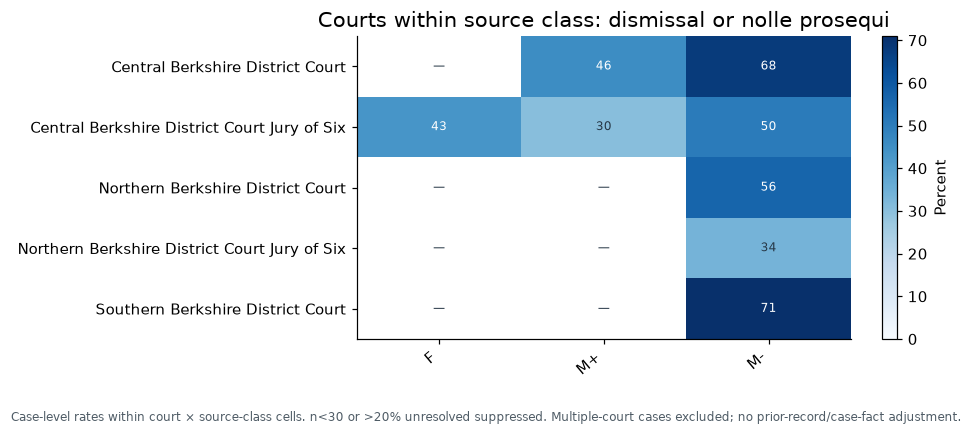

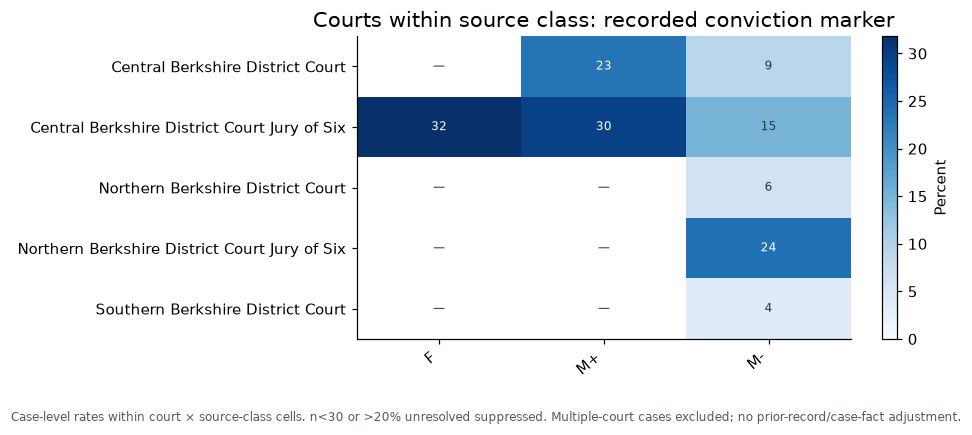

In [25]:
court_rows=[]
for (severity,court),g in dc.groupby(['source_class','court']):
    if court in ['Missing','Multiple / conflicting']:continue
    unknown=g.outcome_unknown.mean()
    eligible_rate=len(g)>=MIN_CELL and unknown<=.2
    court_rows.append({'source_class':severity,'court':court,'cases':len(g),'outcome_unknown_pct':unknown*100,
      'dismissal_nolle_pct':g.outcome.isin(['Dismissal','Nolle prosequi']).mean()*100 if eligible_rate else np.nan,
      'conviction_marker_pct':g.any_conviction.mean()*100 if eligible_rate else np.nan})
court_comparison=pd.DataFrame(court_rows)
table('Q20_court_by_source_class',court_comparison,rows=40)
for metric in ['dismissal_nolle_pct','conviction_marker_pct']:
    matrix=court_comparison.pivot(index='court',columns='source_class',values=metric)
    metric_title={'dismissal_nolle_pct':'dismissal or nolle prosequi','conviction_marker_pct':'recorded conviction marker'}[metric]
    fig,ax=heatmap(matrix,f'Courts within source class: {metric_title}',percent=True,annotate=True)
    finish(fig,'Q20_'+metric,'Case-level rates within court × source-class cells. n<30 or >20% unresolved suppressed. Multiple-court cases excluded; no prior-record/case-fact adjustment.')
answer(20,'Partial','Reportable same-source-class dismissal/nolle and conviction-marker comparisons are shown by court; diversion is unavailable.',
 'Source class is only broad severity. Multiple-court cases, provisional outcomes, missing prior record and case facts limit comparability. No causal court-effect claim.',
 'Case-defendant proxy','Observed disposed criminal cases within court × source class')
contract(20,'Court × source-class heatmap, with n and missingness','Case','Disposition year','Dismissal/nolle and conviction markers','Court × source-class cases','n≥30; unknown≤20%; multiple courts explicit','Validated seriousness, diversion records and fuller controls')

## Q21. Which agencies account for the largest share of filed charges, and how does their offense mix differ?

**Scope: Court and agency patterns.** This question explicitly asks about filed charges. Unlike the case-level questions, its primary unit is a source charge row. Agency is the recorded filing/officer agency, not a complete referral count. Missing agency stays in the denominator; exact-repeat sensitivity is reported.

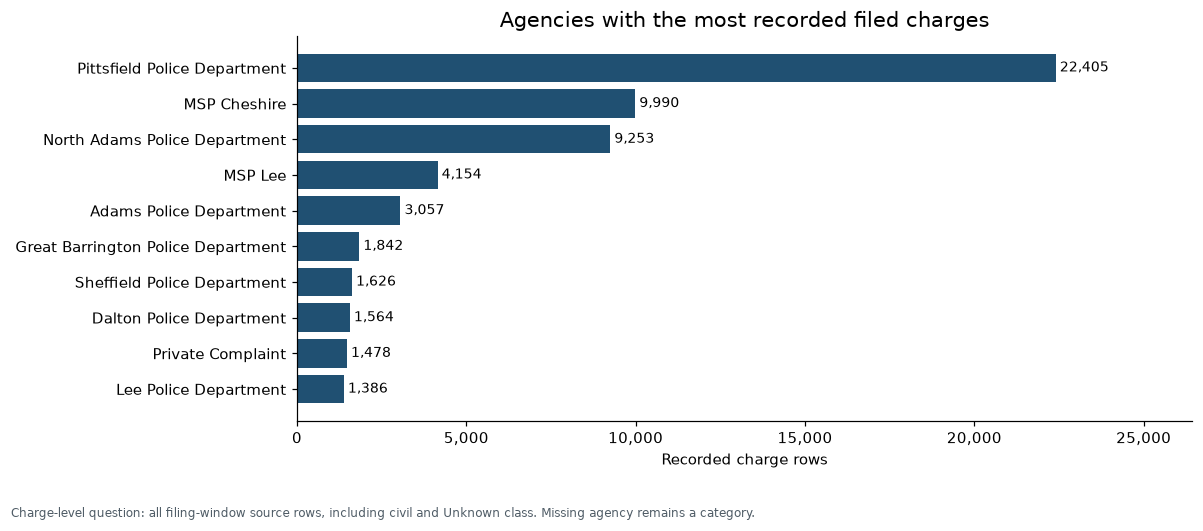

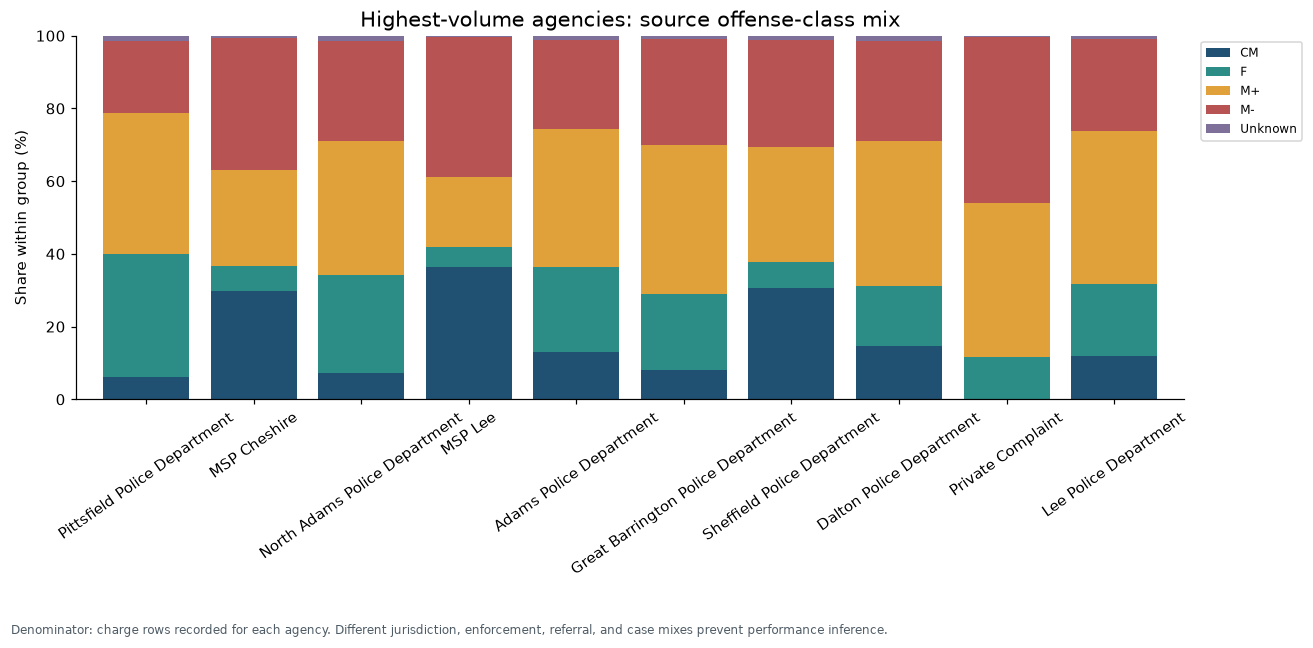

In [26]:
agency=f.agency.fillna('Missing').value_counts().to_frame('filed_charge_rows')
agency['share_all_filed_charge_rows_pct']=agency.filed_charge_rows/len(f)*100
agency['rows_without_exact_repeated_exports']=f.loc[~f.exact_duplicate].agency.fillna('Missing').value_counts().reindex(agency.index,fill_value=0)
table('Q21_filing_agency_shares',agency,rows=30)
agency_mix=pd.crosstab(f.agency.fillna('Missing'),f.offense_class)
table('Q21_agency_offense_class_mix',agency_mix,rows=30)
table('Q21_agency_charge_code_mix',pd.crosstab(f.agency.fillna('Missing'),f.charge_code),rows=15)
leaders=agency.head(10).index
fig,ax=barh(agency.filed_charge_rows.head(10),'Agencies with the most recorded filed charges')
finish(fig,'Q21_agency_volume','Charge-level question: all filing-window source rows, including civil and Unknown class. Missing agency remains a category.')
fig,ax=stacked(agency_mix.reindex(leaders), 'Highest-volume agencies: source offense-class mix',percent=True)
finish(fig,'Q21_agency_class_mix','Denominator: charge rows recorded for each agency. Different jurisdiction, enforcement, referral, and case mixes prevent performance inference.')
answer(21,'Answerable',f'{agency.index[0]} accounts for {agency.iloc[0].share_all_filed_charge_rows_pct:.1f}% of recorded filed charge rows. Agency shares, class mix, and full charge-code mix are tabulated.',
 'Describes supplied filing activity, not all referrals or agency crime prevalence. Source class/description mix is available; a broad offense-category crosswalk is not.',
 'Charge row, explicitly requested','All 2017–2024 initiated charge rows, including Missing agency')
contract(21,'Agency volume bars plus 100% class composition','Charge','Initiation year','Agency charge rows by source class/code','All filed charge rows; per-agency rows for mix','Missing agency retained','None for source-class/code composition')

## Q22. When both amounts are recorded, how often is bail set lower than, equal to, or higher than the amount requested?

**Scope: Bail decisions.** This question explicitly conditions on both amounts being recorded. The conditional event-level answer is observable even though most events lack a request or amount. It must not be presented as the percentage of all hearings, all defendants, or county receipts.

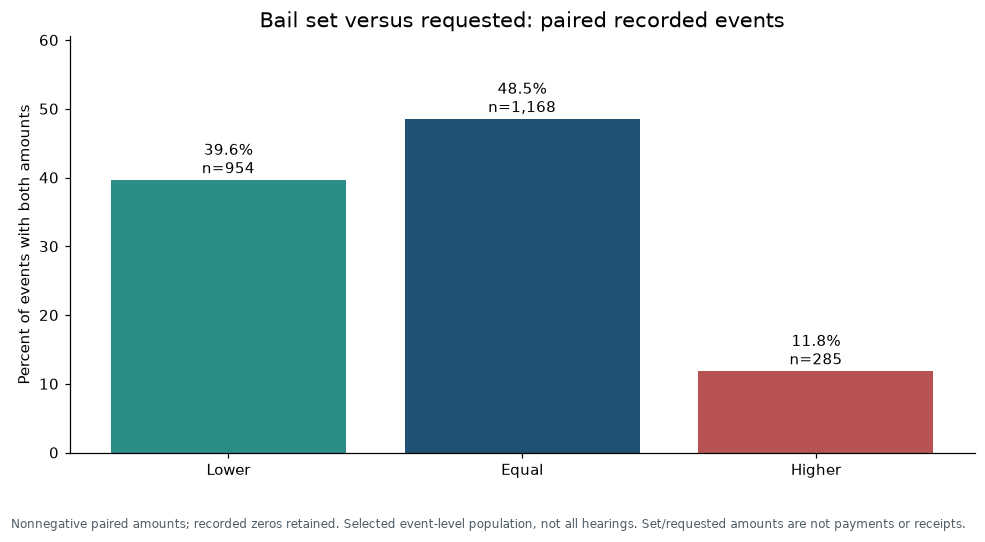

In [27]:
pairs=b.loc[b.requested.notna()&b.set_amount.notna()&b.requested.ge(0)&b.set_amount.ge(0)].copy()
pairs['comparison']=np.select([pairs.set_amount.lt(pairs.requested),pairs.set_amount.eq(pairs.requested)],['Lower','Equal'],default='Higher')
comparison=pairs.comparison.value_counts().reindex(['Lower','Equal','Higher'],fill_value=0).to_frame('events')
comparison['percent_of_paired_events']=comparison.events/len(pairs)*100
table('Q22_paired_bail_comparison',comparison)
first_pair=pairs.sort_values(['bail_date','source_row']).drop_duplicates('case_id')
table('Q22_one_paired_event_per_case_sensitivity',first_pair.comparison.value_counts().reindex(['Lower','Equal','Higher'],fill_value=0).to_frame('case_ids'))
fig,ax=plt.subplots(figsize=(9,5));ax.bar(comparison.index,comparison.percent_of_paired_events,color=[COLORS[1],COLORS[0],COLORS[3]])
for i,v in enumerate(comparison.percent_of_paired_events):ax.text(i,v+1,f'{v:.1f}%\nn={comparison.iloc[i].events:,.0f}',ha='center')
ax.set(title='Bail set versus requested: paired recorded events',ylabel='Percent of events with both amounts',ylim=(0,comparison.percent_of_paired_events.max()+12))
finish(fig,'Q22_requested_vs_set','Nonnegative paired amounts; recorded zeros retained. Selected event-level population, not all hearings. Set/requested amounts are not payments or receipts.')
answer(22,'Answerable',f'Among {len(pairs):,} paired events: lower {comparison.loc["Lower","percent_of_paired_events"]:.1f}%, equal {comparison.loc["Equal","percent_of_paired_events"]:.1f}%, higher {comparison.loc["Higher","percent_of_paired_events"]:.1f}%. Paired events represent {len(pairs)/len(b):.1%} of the bail-event extract in the window.',
 'The answer is conditional on both amounts being recorded; repeated events can weight some cases more heavily. One-paired-event-per-case sensitivity is supplied.',
 'Bail event','Events dated 2017–2024 with both nonnegative amounts recorded')
contract(22,'Lower/equal/higher three-bar chart with n and pair coverage','Bail event','Status date 2017–2024','Paired events in each set-versus-request category','All valid paired events','Missing never replaced with zero','None for the explicitly conditional question')

## Q23. How complete are the race, offense severity, judge, and bail-amount fields, and how does completeness differ across counties?

**Scope: Data quality and reliability.** Berkshire completeness is directly observable. Other-county comparisons are unavailable by design. Both source-row coverage and relevant case/conditional populations are reported. A populated unit field does not establish that a sentence amount exists.

In [28]:
quality=[]
for name,frame,fields in [('Filing rows',f,['race_code','offense_class']),
                         ('Disposed rows',d,['race_code','offense_class','judge']),
                         ('Bail events',b,['race_code','requested','set_amount'])]:
    for field in fields:
        missing=frame[field].isna()|frame[field].eq('Unknown')
        year=frame.initiated_date.dt.year if name=='Filing rows' else frame.disposition_date.dt.year if name=='Disposed rows' else frame.bail_date.dt.year
        quality.append({'population':name,'field':field,'rows':len(frame),'blank_or_unknown_class':int(missing.sum()),
          'missing_pct':missing.mean()*100,'years_available':','.join(str(int(y)) for y in sorted(year.dropna().unique()))})
quality=pd.DataFrame(quality)
table('Q23_berkshire_field_coverage',quality,rows=30)
usability=[]
for name,frame in [('Filing rows',f),('Disposed rows',d),('Bail events',b)]:
    rc=frame.race_code
    usability.append({'population':name,'field':'race','records':len(frame),'blank':int(rc.isna().sum()),
      'explicit_unknown_or_placeholder':int(rc.eq('U').sum()),
      'unverified_code':int((rc.notna()&~rc.isin(['W','B','H','A','U'])).sum()),
      'recorded_zero':np.nan})
    if 'offense_class' in frame:
        oc=frame.offense_class
        usability.append({'population':name,'field':'source severity','records':len(frame),
          'blank':int(oc.eq('Unknown').sum()),'explicit_unknown_or_placeholder':0,
          'unverified_code':int((~oc.isin(['F','M+','M-','CM','Unknown'])).sum()),'recorded_zero':np.nan})
    if 'judge' in frame:
        placeholder=frame.judge.fillna('').str.contains('clerk|no judge|unknown',case=False,regex=True)
        usability.append({'population':name,'field':'judge','records':len(frame),'blank':int(frame.judge.isna().sum()),
          'explicit_unknown_or_placeholder':int(placeholder.sum()),'unverified_code':np.nan,'recorded_zero':np.nan})
    for field in ['requested','set_amount']:
        if field in frame:
            usability.append({'population':name,'field':field,'records':len(frame),'blank':int(frame[field].isna().sum()),
              'explicit_unknown_or_placeholder':0,'unverified_code':int(frame[field].lt(0).sum()),'recorded_zero':int(frame[field].eq(0).sum())})
table('Q23_blank_unknown_placeholder_and_zero_audit',pd.DataFrame(usability),rows=30)
fig,ax=barh(quality.set_index(quality.population+' / '+quality.field).missing_pct,
 'Berkshire coverage of the team’s key fields','Missing within stated population (%)')
ax.axvline(20,color=COLORS[3],ls='--',label='Team threshold: 20%');ax.legend()
finish(fig,'Q23_field_coverage','Blank values and Unknown source class only; explicit Unknown race codes are separately retained, not silently treated as known demographic identity.')
cash=b.loc[b.cash_label]
table('Q23_cash_status_conditional_amount_coverage',pd.Series({'cash_status_events':len(cash),
 'request_missing_pct':cash.requested.isna().mean()*100,'set_missing_pct':cash.set_amount.isna().mean()*100},name='value'))
answer(23,'Partial','Berkshire field completeness, years available, case-level unresolved shares, and cash-status conditional amount coverage are tabulated.',
 'No other-county records are used, so a cross-county completeness difference cannot be calculated. Explicit Unknown and invalid values need separate audit from blanks.',
 'Source row and separately labeled eligible case populations','All records in each stated extract/window; conditional cash-status subset separately')
contract(23,'Missingness bars with threshold and years available','Field × population','Same window for all counties','Missing/unknown/invalid values separately','All relevant records for that field','Blank, explicit Unknown, invalid separated','Other counties for comparative component')

## Team decision table: which common goals are defensible?

The status below answers the literal **23 Objectives**, not a shortened reformulation. Partial results are useful exploratory outputs, but their qualifications must travel with any common visualization. If another county uses a different unit, date basis, outcome hierarchy, or missingness denominator, the charts should not be combined merely because their titles match.

**Strongest immediate common specification candidates:** Q21 (agency share/mix of filed charge rows), Q22 (paired bail request-versus-set, only where those fields exist), and the Berkshire portion of Q23 (coverage). Case-volume trends are a useful companion to Q1 but cannot be titled referral counts. Q3, Q7–Q15, Q17, Q19 and Q20 require the qualifications and coverage checks stated above. Unsupported fields should remain unavailable instead of being filled with proxies.

**No external additions:** Q2 population, Q18 other counties/statewide, and policy/DA-term dates in Q17 are explicitly flagged. No external numerical inputs appear anywhere in this notebook.

In [29]:
QUESTION_METADATA = {1: {'scope': 'Volume and scope', 'objective_question': 'How many cases were referred to the prosecutor each year, and how has that changed over the study period?'}, 2: {'scope': 'Volume and scope', 'objective_question': 'What is the per-capita case rate (cases per 10,000 residents), so counties of different sizes can be compared?'}, 3: {'scope': 'Volume and scope', 'objective_question': 'What share of cases are felonies vs. misdemeanors, and what are the 5 most common offense categories?'}, 4: {'scope': 'Charging decisions', 'objective_question': 'What percentage of referred cases does the prosecutor decline to charge?'}, 5: {'scope': 'Charging decisions', 'objective_question': 'How often is the filed charge different from the arrest/referral charge (upgraded, downgraded, unchanged)?'}, 6: {'scope': 'Charging decisions', 'objective_question': 'What share of cases are diverted to alternative programs instead of prosecuted?'}, 7: {'scope': 'Case outcomes', 'objective_question': 'Of charged cases, what percentage end in dismissal, plea, trial conviction, or acquittal?'}, 8: {'scope': 'Case outcomes', 'objective_question': 'What is the plea rate, and how often do pleas involve a reduced charge?'}, 9: {'scope': 'Case outcomes', 'objective_question': 'What share of cases go to trial, and what is the conviction rate at trial?'}, 10: {'scope': 'Sentencing', 'objective_question': 'What share of convictions result in incarceration vs. probation vs. fines/other?'}, 11: {'scope': 'Sentencing', 'objective_question': 'What is the median sentence length by offense category?'}, 12: {'scope': 'Pretrial and timing', 'objective_question': 'What share of defendants are detained pretrial, and how often is cash bail set?'}, 13: {'scope': 'Pretrial and timing', 'objective_question': 'What is the median time from filing to disposition, and does it differ by case type?'}, 14: {'scope': 'Equity', 'objective_question': 'Do declination, dismissal, and incarceration rates differ by defendant race/ethnicity?'}, 15: {'scope': 'Equity', 'objective_question': 'Do those outcomes differ by sex and age group?'}, 16: {'scope': 'Equity', 'objective_question': 'Do racial disparities remain when you compare within the same offense category and prior-record level?'}, 17: {'scope': 'Trends and context', 'objective_question': 'Did any of the above metrics shift noticeably around a policy change, new DA term, or 2020?'}, 18: {'scope': 'Trends and context', 'objective_question': 'How does this county rank against the state average and the other counties on the team’s core metrics (rates from Q4, Q7, Q10, Q14)?'}, 19: {'scope': 'Case complexity', 'objective_question': 'How does the number of recorded charges per case relate to the time from offense to disposition?'}, 20: {'scope': 'Court and agency patterns', 'objective_question': 'Do dismissal, conviction, and diversion rates differ across courts when comparing cases of the same offense severity?'}, 21: {'scope': 'Court and agency patterns', 'objective_question': 'Which agencies account for the largest share of filed charges, and how does their offense mix differ?'}, 22: {'scope': 'Bail decisions', 'objective_question': 'When both amounts are recorded, how often is bail set lower than, equal to, or higher than the amount requested?'}, 23: {'scope': 'Data quality and reliability', 'objective_question': 'How complete are the race, offense severity, judge, and bail-amount fields, and how does completeness differ across counties?'}}
answer_matrix=pd.DataFrame([ANSWERS[i] for i in range(1,24)]).set_index('question')
answer_matrix.insert(0,'scope',[QUESTION_METADATA[i]['scope'] for i in answer_matrix.index])
answer_matrix.insert(1,'objective_question',[QUESTION_METADATA[i]['objective_question'] for i in answer_matrix.index])
table('all_23_objectives_answer_matrix',answer_matrix,rows=23)
contracts=pd.DataFrame(CONTRACTS).set_index('question')
table('uniform_visualization_contracts',contracts,rows=23)
status_counts=answer_matrix.status.value_counts()
fig,ax=barh(status_counts,'Literal Objectives: answerability with these three files','Questions')
finish(fig,'objective_answerability_summary','Partial does not mean fully comparable. No answer is manufactured for a missing field or external denominator.')
checks={
 'all_23_objectives_assessed':set(ANSWERS)==set(range(1,24)),
 'one_case_row_per_filing_key':fc.index.is_unique,
 'one_case_row_per_disposition_key':dc.index.is_unique,
 'case_outcome_count_reconciles':int(outcomes.cases.sum())==len(dc),
 'sentence_count_reconciles':int(sentence_counts.cases.sum())==len(conv),
 'paired_bail_count_reconciles':int(comparison.events.sum())==len(pairs),
 'bail_links_one_case_each':not bf.case_person.duplicated().any(),
 'original_workbooks_unchanged':all(hashlib.sha256(path.read_bytes()).hexdigest()==source_hashes[name] for name,path in paths.items())}
assert all(checks.values()),checks
table('validation_checks',pd.Series(checks,name='passed'))
summary='# Berkshire: answers to all 23 Objectives\n\nOnly the three supplied Berkshire workbooks are used. Norfolk-specific questions and the later final shortlist are outside this notebook.\n\n'
for number,row in answer_matrix.iterrows():
    summary+=f'## Q{number}. {row["objective_question"]}\n\n**{row["status"]}.** {row["answer"]}\n\nLimitation: {row["limitation_or_missing_input"]}\n\n'
(OUT/'answers_to_23_objectives.md').write_text(summary,encoding='utf8')
manifest={'analytical_inputs':list(p.name for p in paths.values()),'external_numerical_inputs':[],
 'question_source':'Objectives Q1–Q23 in the shared question document',
 'source_hashes':source_hashes,'checks':checks,'figures':FIGURES,'tables':list(TABLES),
 'units':'case-defendant proxy except explicitly charge-level Q21 and event-level Q22',
 'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':plt.matplotlib.__version__}}
(OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf8')
print(f'Completed all 23 Objectives: {len(FIGURES)} figures, {len(TABLES)} tables; no external numerical inputs. Source workbooks unchanged.')

## Selected results from this run

### Q07 case outcome distribution

| outcome | cases | percent_of_observed_disposed_cases |
| --- | --- | --- |
| Trial conviction | 114 | 0.37 |
| Guilty plea | 4294 | 14.03 |
| Conviction · route unknown | 218 | 0.71 |
| CWOF | 4550 | 14.87 |
| Acquittal | 299 | 0.98 |
| Nolle prosequi | 3051 | 9.97 |
| Dismissal | 11416 | 37.31 |
| Other continuation | 655 | 2.14 |

[Full results table](published-results/Q07_case_outcome_distribution.csv)

### Q22 paired bail comparison

| comparison | events | percent_of_paired_events |
| --- | --- | --- |
| Lower | 954 | 39.63 |
| Equal | 1168 | 48.53 |
| Higher | 285 | 11.84 |

[Full results table](published-results/Q22_paired_bail_comparison.csv)
